# **Minimal biomarker panel selection in lung adenocarcinoma using quantum optimisation**

**Team Gene42** · Qiskit Fall Fest 2026 · Khalifa University

Mohamed Irfan · Bogdan Egorov · Jayanth Venkatesan · Hasmik Chilingaryan  — University of Birmingham Dubai

**Aim.** Choose a 4-gene panel that separates LUAD from non-cancerous samples. Gene selection is written as an mRMR QUBO (following Von Dollen et al., arXiv:2104.04049: Pearson relevance and redundancy, a size penalty λ, k = 4) and solved with QAOA in Qiskit. We compare it with classical solvers and feature-selection methods, and we also run it on a real IBM quantum computer.

**Quantum hardware.** The full-pool 16-qubit QUBO was run as QAOA at depth p = 3 on IBM's `ibm_marrakesh` superconducting processor (Qiskit Runtime, SamplerV2, level-3 transpilation). We used three seeds, with 54–67 circuit executions of 1024 shots each per seed, driven by COBYLA. These are real jobs on the public queue, not a noise-model simulation. The saved logs are included, so the notebook reproduces every hardware number without an IBM account (Phase 5.2.1, 7.4b).

- On hardware, 7.7–15.2% of final samples had exactly four genes, against 2.8% for uniform random sampling. Noiseless Aer at the same depth gave 13.4%, so the hardware stayed close to the ideal simulation.
- One of the three seeds returned the exact optimum as its best size-4 panel. The optimum appeared only once in 1024 shots, and the panel was picked by a classical post-selection step, so we do not claim the hardware "solved" the QUBO. We report the hardware as a feasibility test, not as a quantum advantage.
- Aer simulation is still the main QAOA benchmark, because the nested CV needs hundreds of runs that the QPU time we had could not cover.

**Approach in short.** We only have 26 patients, so one train/test split would be very noisy. The whole pipeline (gene shortlist, QUBO, every solver) is repeated inside each training fold of a patient-level, repeated, stratified CV, and panels are scored only on patients the pipeline did not see. The final panel is then produced once on all 26 patients; the organisers' hidden test set is the real held-out check. Panels are scored with the organisers' fixed classifier (standardised logistic regression, as in `panel_checker.py`).

---
## Phase 0 — Setup
Library versions are pinned and every setting lives in the config cell below. A CPU runtime is enough; nothing here uses a GPU.

In [1]:
# 0.1  Install pinned dependencies (uncomment as needed)
!pip install -q numpy pandas scikit-learn scipy matplotlib seaborn openpyxl
!pip install -q qiskit==2.6.1 qiskit-aer==0.18.0
!pip install -q pylatexenc        # needed for the circuit drawing in 7.2c
!pip install -q qiskit-ibm-runtime   # only needed for RUN_HARDWARE = True (5.2.1)


In [2]:
# 0.2  Imports
import time, pickle, random, warnings
from math import comb
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import rankdata
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from scipy.optimize import minimize

from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression, LassoCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.pipeline import make_pipeline

import qiskit, qiskit_aer, sklearn, scipy
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit_aer import AerSimulator

# warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'figure.figsize': (10, 5), 'font.size': 11})

VERSIONS = dict(numpy=np.__version__, pandas=pd.__version__, scipy=scipy.__version__,
                sklearn=sklearn.__version__, qiskit=qiskit.__version__, qiskit_aer=qiskit_aer.__version__)
print("Library versions:", VERSIONS)

Library versions: {'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'sklearn': '1.6.1', 'qiskit': '2.6.1', 'qiskit_aer': '0.18.0'}


In [3]:
# 0.3  Global config, seeds, run log
SEED  = 42
SEEDS = [42, 123, 256, 789, 1024]   # seeds for every stochastic method
K     = 4                           # panel size

# Step 1 — patient-level nested CV (outer loop)
N_OUTER_SPLITS  = 5
N_OUTER_REPEATS = 3

# Step 2 — shortlist funnel (runs on TRAINING patients only)
INNER_SPLITS = 5
INNER_REPEATS = 10          # stability-selection repeats inside each outer-training set
INNER_REPEATS_FINAL = 20    # ... for the final run on the full team pool
TOP_N_RELEVANCE = 250
MIN_LFC = 0.5
CORR_THRESHOLD = 0.7
GENES_PER_CLUSTER = 2
STABILITY_THRESHOLD = 0.50
MIN_SHORTLIST, MAX_SHORTLIST = 12, 16     # <= 16 qubits keeps the statevector small

# Step 3 — QUBO
ALPHA   = 1.0               # α: reward for relevant genes   (|corr| with the label)
BETA    = 1.0               # β: penalty for redundant genes. Overwritten by Phase 6.0 when AUTO_BETA = True
BETA_GRID = [0.1, 0.25, 0.3, 0.4, 0.5, 0.75, 1.0]   # candidates for β selection (β=0 would drop all pairwise terms, i.e. no real QUBO)
AUTO_BETA = True            # True: choose β by nested CV (Phase 6.0); False: use BETA as set above
LAMBDA0 = 10.0              # λ: penalty for a panel size other than K (starting value; doubled until wrong sizes cannot win)

# Step 4 — QAOA
QAOA_MAXITER   = 100        # COBYLA iterations = circuit executions during optimisation
QAOA_SHOTS     = 1024       # shots per circuit execution
QAOA_REPS_OUTER = [2]       # depth(s) used inside the outer CV
QAOA_REPS_FINAL = [1, 2, 3] # depths used in the full-pool run
QAOA_MAIN = 'QAOA p=2'      # the QAOA row used in headline comparisons

# Optional permutation test of the *whole* nested procedure
RUN_PERMUTATION = True
N_PERMS = 50

# Compute budget (units are reported in the budget table in Phase 6)
BUDGET_CIRCUITS = QAOA_MAXITER + 1                 # QAOA circuit runs (+1 final sampling run)
BUDGET_SHOTS    = BUDGET_CIRCUITS * QAOA_SHOTS     # total bitstrings QAOA samples


random.seed(SEED); np.random.seed(SEED)
run_log = []
def log_result(method, library, seed, settings, runs, shots, runtime_s, panel):
    run_log.append(dict(method=method, library=library, seed=seed, settings=settings,
                        runs=runs, shots=shots, runtime_s=round(float(runtime_s), 3), panel=panel))

print(f"seed={SEED}  seeds={SEEDS}  k={K}  QAOA budget: {BUDGET_CIRCUITS} circuits × {QAOA_SHOTS} shots = {BUDGET_SHOTS} bitstrings")

seed=42  seeds=[42, 123, 256, 789, 1024]  k=4  QAOA budget: 101 circuits × 1024 shots = 103424 bitstrings


---
## Phase 1 — Data preparation
We use the organisers' log2(CPM+1) matrix, restricted to our 26 patients. The steps here (gene-symbol cleanup and the expression filter) do not use the labels, so running them once on all patients does not leak information into the later selection.

The matrix is already normalised, so raw library sizes are not available. The funnel's library-size check therefore uses the number of detected genes per patient as a proxy.

In [4]:
# 1.1  Load the organisers' log-normalised matrix + metadata
MATRIX_PATH = "log(CPM_Matrix) DATA - Biotrack.xlsx"      # normalised matrix (genes × patients)
META_PATH   = "ADOMICS Metadata_Kh.csv.xlsx"
raw  = pd.read_excel(MATRIX_PATH, index_col=0)
meta = pd.read_excel(META_PATH)
raw.columns = raw.columns.astype(str); meta['patient_id'] = meta['patient_id'].astype(str)

# keep ONLY our own team pool (task rule), in the file's column order
pool = set(meta['patient_id'])
missing = sorted(pool - set(raw.columns))
assert not missing, f"Patients in metadata but not in the matrix: {missing}"
extra = [c for c in raw.columns if c not in pool]
if extra: print(f"Ignoring {len(extra)} patients not in our pool: {extra}")
raw = raw[[c for c in raw.columns if c in pool]]

print(f"Normalised matrix : {raw.shape[0]} genes × {raw.shape[1]} patients")
print(f"Metadata          : {meta.shape[0]} patients")
print(f"Labels            : {meta['histology'].value_counts().to_dict()}")

Normalised matrix : 29527 genes × 26 patients
Metadata          : 26 patients
Labels            : {'LUAD': 14, 'Normal': 12}


In [5]:
# 1.2  Labels + transpose (patients × genes)
label_map = meta.set_index('patient_id')['histology'].map({'LUAD': 1, 'Normal': 0})
label_map.name = 'label'
y_all = label_map.reindex(raw.columns.tolist())
assert y_all.notna().all(), "Some patients have no label!"

X_raw = raw.T.copy(); X_raw.index.name = 'patient_id'
print(f"{X_raw.shape[0]} patients × {X_raw.shape[1]} genes | LUAD: {(y_all==1).sum()}, Normal: {(y_all==0).sum()}")

26 patients × 29527 genes | LUAD: 14, Normal: 12


In [6]:
# 1.3  Label-free gene cleanup
X_clean = X_raw

# drop duplicated gene symbols (keep first)
n_dup = int(X_clean.columns.duplicated().sum())
X_clean = X_clean.loc[:, ~X_clean.columns.duplicated()]
print(f"Dropped {n_dup} duplicated gene columns")

Dropped 0 duplicated gene columns


In [7]:
# 1.4  Data is already log2(CPM+1): filter only, no second normalisation
vals = X_clean.values.astype(float)
print(f"Value range: min={vals.min():.2f}, max={vals.max():.2f}, exact zeros={(vals == 0).mean():.1%}")
assert vals.min() >= 0 and vals.max() < 40, "This does not look like log(CPM+1) – check MATRIX_PATH"

LOG_BASE    = 2          # log2(CPM+1): the maximum value (17.2) is above the ceiling for ln (13.8) and log10 (6.0)
LOG_FLOOR   = np.log(2) / np.log(LOG_BASE)      # log_base(CPM+1) at CPM = 1  (= 1.0 for log2)
MIN_SAMPLES = 12                                  # expressed (CPM > 1) in at least 12 of 26 patients
expressed   = (X_clean > LOG_FLOOR).sum(axis=0) >= MIN_SAMPLES
X_filtered  = X_clean.loc[:, expressed]
print(f"Expression filter: {expressed.sum()} genes kept, {(~expressed).sum()} dropped")

X_norm = X_filtered

# The matrix is already CPM-normalised, so raw library sizes are not available.
# The number of detected genes per patient is used as a library-size proxy in the funnel (stage 2).
lib_sizes_filt = (X_clean > 0).sum(axis=1).astype(float)
print("Library-size proxy: number of detected genes per patient")

print(f"Matrix used downstream: {X_norm.shape[0]} patients × {X_norm.shape[1]} genes")

# numpy views for the rest of the notebook
gene_names  = np.array(X_norm.columns)
Xn          = X_norm.values.astype(float)
y           = y_all.values.astype(int)
patient_ids = X_norm.index.values
lib_raw     = lib_sizes_filt.values.astype(float)

Value range: min=0.00, max=17.21, exact zeros=42.7%
Expression filter: 14445 genes kept, 15082 dropped
Library-size proxy: number of detected genes per patient
Matrix used downstream: 26 patients × 14445 genes


### Quality check
The number of detected genes per patient (our library-size proxy) is the only technical covariate we check. It is not used to select genes.

In [8]:
# 1.5  QC: library-size proxy (diagnostic only)
lib_auc = roc_auc_score(y, lib_raw); lib_auc = max(lib_auc, 1 - lib_auc)
print(f"Detected-genes-only AUROC: {lib_auc:.3f}", "⚠ possible confound" if lib_auc > 0.85 else "✓ not a strong predictor")
z_lib = np.abs(stats.zscore(lib_raw))
print("Detected-genes outliers (|z|>2):", list(patient_ids[z_lib > 2]) or "none")

Detected-genes-only AUROC: 0.714 ✓ not a strong predictor
Detected-genes outliers (|z|>2): none


---
## Phase 2 — Patient-level split design
With 26 patients, one split would leave about 8 validation samples and a very noisy AUROC. We therefore use `StratifiedGroupKFold` (5 folds, repeated 3 times with different seeds), grouped by patient so that no patient appears on both sides of a split.

Inside every outer training set we run the full method (shortlist, QUBO, all solvers). The outer validation patients are used only to score the panels that came out of that run. The final panel comes from running the same pipeline once on all 26 patients.

In [9]:
# 2.1  Outer splits (patient-level)
n_min_class = int(min(y.sum(), (1 - y).sum()))
N_OUTER_SPLITS = int(min(N_OUTER_SPLITS, n_min_class))

def outer_splits(rep, offset=0):
    sgkf = StratifiedGroupKFold(n_splits=N_OUTER_SPLITS, shuffle=True, random_state=SEED + offset + rep)
    return list(sgkf.split(Xn, y, groups=patient_ids))

tbl = []
for rep in range(N_OUTER_REPEATS):
    for f, (tr, va) in enumerate(outer_splits(rep)):
        assert not set(patient_ids[tr]) & set(patient_ids[va]), "patient appears in both train and validation!"
        tbl.append(dict(repeat=rep, fold=f, n_train=len(tr), n_val=len(va),
                        val_LUAD=int(y[va].sum()), val_Normal=int((1 - y[va]).sum())))
print(f"Outer CV: {N_OUTER_SPLITS}-fold × {N_OUTER_REPEATS} repeats = {len(tbl)} outer splits (patient-level, stratified)")
display(pd.DataFrame(tbl).head(N_OUTER_SPLITS))

Outer CV: 5-fold × 3 repeats = 15 outer splits (patient-level, stratified)


,repeat,fold,n_train,n_val,val_LUAD,val_Normal
0,0,0,20,6,1,5
1,0,1,21,5,4,1
2,0,2,21,5,1,4
3,0,3,21,5,3,2
4,0,4,21,5,5,0


---
## Phase 3 — Shortlist funnel
Going from ~14,000 genes to a QUBO that a simulator can handle (at most 16 qubits) needs a shortlist. The funnel has four stages: (1) keep genes with |log2FC| ≥ 0.5 and take the top 250 by single-gene AUROC; (2) drop genes whose signal disappears after adjusting for the library-size proxy (detected genes per patient); (3) cluster genes with |r| > 0.7 and keep at most two per cluster; (4) repeat on resampled training folds and keep genes selected in at least 50% of repeats (stability selection). The shortlist is 12–16 genes.

The funnel is a function of the training rows only, so it can be re-run inside every outer fold. AUROC, log fold change and the library-size-proxy adjustment are vectorised over all genes at once.

In [10]:
# 3.1  Vectorised statistics
def auroc_vec(X, yv):
    # AUROC (direction-free, max(a,1-a)) for every column of X at once.
    r = rankdata(X, axis=0)                      # average ranks -> identical to sklearn with ties
    n1 = int(yv.sum()); n0 = len(yv) - n1
    u = r[yv == 1].sum(axis=0) - n1 * (n1 + 1) / 2.0
    a = u / (n1 * n0)
    return np.maximum(a, 1 - a)

def lfc_vec(X, yv):
    return np.abs(X[yv == 1].mean(axis=0) - X[yv == 0].mean(axis=0))


In [11]:
# 3.2  Stability-selection funnel on TRAINING rows only
def funnel_frequencies(X, yv, lib, seed, n_repeats):
    # Run the funnel inside resampled folds of (X, yv). Returns per-gene selection frequency.
    n, G = X.shape
    splits = int(min(INNER_SPLITS, yv.sum(), (1 - yv).sum()))
    rskf = RepeatedStratifiedKFold(n_splits=splits, n_repeats=n_repeats, random_state=seed)
    log_lib = np.log2(lib + 1)
    counts = np.zeros(G); n_it = 0
    for tr, _ in rskf.split(X, yv):
        Xt, yt = X[tr], yv[tr]
        a = auroc_vec(Xt, yt); l = lfc_vec(Xt, yt)

        # Stage 1: relevance screen
        cand = np.where(l >= MIN_LFC)[0]
        if len(cand) < 10: continue
        cand = cand[np.argsort(-a[cand], kind='stable')][:TOP_N_RELEVANCE]

        # Stage 2: library-size check (residualise on log detected-gene count, the library-size proxy)
        ll = log_lib[tr]; llc = ll - ll.mean()
        Xc = Xt[:, cand]; Xcc = Xc - Xc.mean(axis=0)
        denom = float(llc @ llc)
        if denom > 0:
            slope = (llc @ Xcc) / denom
            adj = auroc_vec(Xcc - np.outer(llc, slope), yt)
            keep = cand[adj >= 0.6]
        else:
            keep = cand
        if len(keep) < 8: keep = cand[:50]

        # Stage 3: redundancy control (hierarchical clustering on |Pearson|)
        C = np.abs(np.nan_to_num(np.corrcoef(Xt[:, keep].T)))
        D = np.clip(1 - C, 0, None); np.fill_diagonal(D, 0); D = (D + D.T) / 2
        cl = fcluster(linkage(squareform(D, checks=False), method='average'), t=1 - CORR_THRESHOLD, criterion='distance')
        sel = []
        for c in np.unique(cl):
            mem = keep[cl == c]
            sel.extend(mem[np.argsort(-a[mem], kind='stable')][:GENES_PER_CLUSTER])
        counts[sel] += 1; n_it += 1
    return counts / max(n_it, 1)

def select_shortlist(X, yv, lib, seed, n_repeats):
    # Stage 4+5: stable genes -> shortlist of MIN..MAX genes. Uses ONLY the rows passed in.
    freq = funnel_frequencies(X, yv, lib, seed, n_repeats)
    auc_full = auroc_vec(X, yv)
    order = np.lexsort((-auc_full, -freq))              # primary: frequency, tie-break: AUROC
    n_sel = int(np.clip((freq >= STABILITY_THRESHOLD).sum(), MIN_SHORTLIST, MAX_SHORTLIST))
    return order[:n_sel], freq

---
## Phase 4 — QUBO construction
A panel is a bitstring ω with ω_i = 1 if gene i is selected. Its energy is

$$E(\omega)\;=\;-\alpha\sum_i r_i\,\omega_i\;+\;\beta\sum_{i<j} c_{ij}\,\omega_i\omega_j\;+\;\lambda\Big(\sum_i\omega_i-k\Big)^2$$

with relevance r_i = |corr(gene i, label)|, redundancy c_ij = |corr(gene i, gene j)|, and k = 4. Only the ratio α/β changes which panel wins. Expanding the square gives the upper-triangular matrix used by all solvers: Q_ii = −α r_i + λ(1 − 2k) and Q_ij = β c_ij + 2λ for i < j.

Relevance and redundancy are computed on the training patients of the current fold only. λ is checked by brute force over all 2^n bitstrings (n ≤ 16) and doubled until no wrong-size bitstring beats the best size-4 panel.

In [12]:
# 4.1  QUBO helpers
# A. All 2^n bitstrings (bit i of the integer = qubit i, Qiskit little-endian)
_BITS = {}
def get_bits(n):
    if n not in _BITS:
        idx = np.arange(2 ** n)
        bits = ((idx[:, None] >> np.arange(n)) & 1).astype(float)
        _BITS[n] = (bits, bits.sum(axis=1).astype(int))
    return _BITS[n]


# B. Relevance r_i and redundancy c_ij (computed on the rows passed in = training rows only)
def qubo_inputs(Xs, yv):
    """Returns (rel, red_upper). red_upper is strictly upper-triangular: each pair appears once."""
    Xs = np.asarray(Xs, dtype=float); yv = np.asarray(yv, dtype=float).reshape(-1)
    if Xs.ndim != 2 or Xs.shape[0] != len(yv):
        raise ValueError("Xs must be (n_samples, n_genes), aligned with yv.")
    if not np.isfinite(Xs).all() or not np.isfinite(yv).all():
        raise ValueError("Xs and yv must be finite before correlation.")
    C = np.abs(np.nan_to_num(np.corrcoef(np.column_stack([Xs, yv]), rowvar=False), nan=0.0, posinf=0.0, neginf=0.0))
    return C[:-1, -1].copy(), np.triu(C[:-1, :-1], k=1)


# C. The QUBO matrix: objective part (α, β) + cardinality part (λ)
def qubo_objective_matrix(rel, red, alpha, beta):
    """Upper-triangular mRMR part only:  diagonal = -α·relevance,  upper triangle = β·redundancy,  lower = 0."""
    M = beta * np.triu(np.asarray(red, dtype=float), k=1)
    M[np.diag_indices(len(rel))] = -alpha * np.asarray(rel, dtype=float)
    return M

def build_qubo(rel, red, alpha, beta, lam, k):
    """Q = objective part + λ(Σω − k)² expanded:  Q_ii += λ(1−2k),  Q_ij += 2λ  (i<j)."""
    n = len(rel)
    if np.shape(red) != (n, n): raise ValueError("red must have shape (n_genes, n_genes).")
    if not (0 <= k <= n): raise ValueError("k must be between 0 and n.")
    if alpha < 0 or beta < 0 or lam < 0: raise ValueError("alpha, beta and lambda must be nonnegative.")
    Q = qubo_objective_matrix(rel, red, alpha, beta) + 2 * lam * np.triu(np.ones((n, n)), k=1)
    Q[np.diag_indices(n)] += lam * (1 - 2 * k)
    return Q

def cost_vector(Q, bits):
    return np.einsum("bi,ij,bj->b", bits, Q, bits)


# D. λ check: every wrong-size bitstring must lose to the best size-k panel
def choose_lambda(rel, red, alpha, beta, k, bits, sizes, lam0=LAMBDA0, max_doublings=30):
    if lam0 <= 0: raise ValueError("lam0 must be positive.")
    if not np.any(sizes == k) or not np.any(sizes != k): raise ValueError("Need both valid- and invalid-size bitstrings.")
    lam = float(lam0)
    for _ in range(max_doublings + 1):
        Q = build_qubo(rel, red, alpha, beta, lam, k)
        costs = cost_vector(Q, bits)
        if costs[sizes != k].min() > costs[sizes == k].min() + 1e-9:
            return lam, Q, costs
        lam *= 2
    raise RuntimeError(f"Could not verify cardinality enforcement within {max_doublings} doublings.")

print(f"QUBO helpers ready.  α={ALPHA}  β={BETA}  λ₀={LAMBDA0}")

QUBO helpers ready.  α=1.0  β=1.0  λ₀=10.0


---
## Phase 5 — Solvers
All methods use the same shortlist, the same Q and the same seeds.

| Method | Type | Search space | Seeds |
|---|---|---|---|
| Exact enumeration | classical, solves the QUBO exactly | all C(n,4) panels | deterministic |
| QAOA (Qiskit + Aer) | quantum, penalty QUBO | all 2^n bitstrings (can return a wrong size) | 5 |
| Simulated annealing | classical, same penalty QUBO | 2^n | 5 |
| Random search | classical | 2^n | 5 |
| Top-4 AUROC, LASSO, RFE, Random Forest, greedy mRMR | feature selection | – | 5 for stochastic ones |
| Random 4-gene panel | baseline | – | 5 |

**Budgets.** Simulated annealing and random search are run twice: once with as many evaluations as QAOA has circuit executions, and once with as many as the total shots QAOA samples (circuits × shots).

**Output.** QAOA samples its final optimised circuit and returns the lowest-energy bitstring seen. SA and random search return their best visited state, which favours them slightly. Wrong-size outputs are counted; to score one, we use the best size-4 state that method saw.

In [13]:
# 5.1  Classical QUBO solvers: simulated annealing + random search
def sa_qubo(Qs, bits_sizes, n_iter, seed, T0=1.0, T1=0.01):
    # Single-bit-flip simulated annealing on the penalty QUBO (Qs is Q / max|Q|).
    # Returns (best raw bitstring int, best size-K bitstring int or None).
    rng = np.random.default_rng(seed); n = Qs.shape[0]
    d = np.diag(Qs).copy(); A = np.triu(Qs, 1); A = A + A.T
    pow2 = 1 << np.arange(n)
    x = rng.integers(0, 2, n).astype(float); f = A @ x
    E = float(d @ x + 0.5 * x @ A @ x); cnt = int(x.sum())
    best_E, best_x = E, x.copy(); bv_E, bv_x = np.inf, None
    if cnt == K: bv_E, bv_x = E, x.copy()
    Ts = np.geomspace(T0, T1, n_iter); flips = rng.integers(0, n, n_iter); us = rng.random(n_iter)
    for t in range(n_iter):
        i = flips[t]; s = 1.0 - 2.0 * x[i]; dE = s * (d[i] + f[i])
        if dE <= 0 or us[t] < np.exp(-dE / Ts[t]):
            x[i] += s; f += s * A[:, i]; E += dE; cnt += int(s)
            if E < best_E - 1e-12: best_E, best_x = E, x.copy()
            if cnt == K and E < bv_E - 1e-12: bv_E, bv_x = E, x.copy()
    to_int = lambda v: int(v @ pow2)
    return to_int(best_x), (None if bv_x is None else to_int(bv_x))

def random_search(cost, sizes, n_samples, seed):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(cost), n_samples)
    raw = int(idx[np.argmin(cost[idx])])
    ok = idx[sizes[idx] == K]
    val = int(ok[np.argmin(cost[ok])]) if len(ok) else None
    return raw, val
print("SA / random search ready.")

SA / random search ready.


In [14]:
# 5.2  QAOA with Qiskit (circuit) + Aer (shot-based simulator)
AER = AerSimulator(method='statevector')

def qaoa_circuit(Qs, reps):
    # QAOA ansatz for  min x^T Q x.  With x=(1-Z)/2:  E = const + sum h_i Z_i + sum J_ij Z_i Z_j
    #   h_i = -Q_ii/2 - (sum_{j!=i} Q_ij)/4 ,  J_ij = Q_ij/4
    n = Qs.shape[0]
    d = np.diag(Qs); U = np.triu(Qs, 1)
    h = -d / 2 - (U.sum(axis=1) + U.sum(axis=0)) / 4
    J = U / 4
    gam, bet = ParameterVector('gamma', reps), ParameterVector('beta', reps)
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for l in range(reps):
        for i in range(n):
            qc.rz(2 * gam[l] * float(h[i]), i)                       # exp(-i γ h Z)
        for i, j in zip(*np.nonzero(J)):
            qc.rzz(2 * gam[l] * float(J[i, j]), int(i), int(j))       # exp(-i γ J ZZ)
        qc.rx(2 * bet[l], range(n))                                   # mixer exp(-i β X)
    qc.measure_all()
    return qc, list(gam) + list(bet)

def run_qaoa(Qs, cost_s, sizes, opt_idx, reps, seed, maxiter=QAOA_MAXITER, shots=QAOA_SHOTS):
    # One QAOA run: COBYLA over (gamma, beta); every objective evaluation = 1 circuit execution with `shots` shots.
    rng = np.random.default_rng(seed)
    qc, params = qaoa_circuit(Qs, reps)
    x0 = np.concatenate([rng.uniform(0, np.pi, reps), rng.uniform(0, np.pi / 2, reps)])
    n_circ = [0]

    def sample(vals):
        bound = qc.assign_parameters(dict(zip(params, vals)))
        n_circ[0] += 1
        counts = AER.run(bound, shots=shots, seed_simulator=int(rng.integers(2 ** 31 - 1))).result().get_counts()
        idx = np.fromiter((int(b, 2) for b in counts), dtype=np.int64, count=len(counts))
        cnt = np.fromiter(counts.values(), dtype=np.int64, count=len(counts))
        return idx, cnt

    def objective(vals):
        idx, cnt = sample(vals)
        return float((cost_s[idx] * cnt).sum() / shots)

    t0 = time.perf_counter()
    res = minimize(objective, x0, method='COBYLA', options={'maxiter': maxiter, 'rhobeg': 0.3})
    idx, cnt = sample(res.x)                                  # final sampling of the optimised circuit
    runtime = time.perf_counter() - t0

    e = cost_s[idx]
    raw = int(idx[np.argmin(e)])                              # lowest-energy sampled bitstring (like MinimumEigenOptimizer)
    ok = sizes[idx] == K
    val = int(idx[ok][np.argmin(e[ok])]) if ok.any() else None
    top = np.argsort(-cnt)[:5]
    return dict(raw=raw, valid=val, runtime=runtime, circuits=n_circ[0], shots=n_circ[0] * shots,
                frac_valid=float(cnt[ok].sum() / shots), p_opt=float(cnt[idx == opt_idx].sum() / shots),
                top_samples=[(int(idx[t]), int(cnt[t])) for t in top], params=res.x.tolist())
print("QAOA ready. Aer method:", AER.options.method)

QAOA ready. Aer method: statevector


### 5.2.1 QAOA on IBM hardware
This section adapts the standard QAOA pipeline to run on physical superconducting quantum hardware via the Qiskit Runtime Service.

The quantum circuit is optimised using Qiskit's preset_pass_manager of optimization level 3. A classical COBYLA optimizer iteratively evaluates the QUBO objective function by sending parameterized circuits to the hardware via SamplerV2.

The total hardware usage is dictated by the classical optimizer's maximum iterations (maxiter) multiplied by the number of samples taken per circuit execution (shots). COBYLA can stop before maxiter once its step size has shrunk to the tolerance, which is what happened in all three runs (53 to 66 evaluations against `QAOA_MAXITER = 100`; with the final sampling run that is 54 to 67 circuit executions).

Following the final parameter optimization, a concluding sample is drawn from the hardware. The code parses these readouts and returns the lowest-energy raw bitstring seen, the lowest-energy valid state (exactly K=4 genes), the total cloud execution time, the frequency of valid states, and the top 5 most frequently sampled bitstrings overall.

The runs are the full-pool QUBO at the deepest depth (p = 3), seeds 42, 256 and 1024, one job per COBYLA evaluation on the public queue. The raw logs of these three runs are public in the team repository ([`seeds/`](https://github.com/irfanizzath/QAOA-LUAD-Biomarker-Selection/tree/main/seeds), files `seed42.txt`, `seed256.txt`, `seed1024.txt`), and the notebook downloads them from there at run time. It therefore runs end to end without an IBM account and without uploading any files: with `RUN_HARDWARE = False` (the default) the logs are fetched from GitHub and nothing is submitted. To re-run on hardware, set `RUN_HARDWARE = True` and paste an IBM Quantum API key into `IBM_TOKEN` in the cell below; the new logs are then written to the runtime and used instead of the GitHub copies. The runtime reported is wall-clock and includes the time spent waiting in the queue, so it is not QPU time.

In [15]:
# ── 5.2.1 Qiskit Runtime (Superconductor Quantum Hardware) ──
import re
import urllib.request

def get_service():
    # uses the key pasted into IBM_TOKEN below; if it is left empty, falls back to an account saved on this machine
    from qiskit_ibm_runtime import QiskitRuntimeService
    return QiskitRuntimeService(channel=IBM_CHANNEL, token=IBM_TOKEN) if IBM_TOKEN else QiskitRuntimeService()

def run_qaoa_ibm(Qs, cost_s, sizes, opt_idx, reps, seed, K, backend_name="ibm_marrakesh", maxiter=QAOA_MAXITER, shots=QAOA_SHOTS):
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler   # imported here so the notebook still loads without it
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    # IBM Backend Setup
    service = get_service()
    backend = service.backend(backend_name)
    pm = generate_preset_pass_manager(optimization_level=3, backend=backend) # Hardware Optimisation for noise reduction

    rng = np.random.default_rng(seed)
    qc, params = qaoa_circuit(Qs, reps) # Generate the base circuit
    isa_qc = pm.run(qc)

    x0 = np.concatenate([rng.uniform(0, np.pi, reps), rng.uniform(0, np.pi / 2, reps)])
    n_circ = [0]; trace = []

    # Initialize the Sampler directly with the backend mode for Open Plan execution
    sampler = Sampler(mode=backend)

    def sample_ibm(vals):
        bound_qc = isa_qc.assign_parameters(vals) # Assign current optimizer values to the transpiled circuit
        n_circ[0] += 1

        # Submit job to the public queue
        job = sampler.run([bound_qc], shots=shots)
        result = job.result()

        # Extract counts from V2 primitive structure
        pub_result = result[0]
        counts = pub_result.data.meas.get_counts()

        idx = np.fromiter((int(b, 2) for b in counts), dtype=np.int64, count=len(counts))
        cnt = np.fromiter(counts.values(), dtype=np.int64, count=len(counts))
        return idx, cnt

    def objective_ibm(vals):
        idx, cnt = sample_ibm(vals)
        cost = float((cost_s[idx] * cnt).sum() / shots)
        trace.append(cost)
        print(f"  iter {n_circ[0]:>4d} | cost = {cost:.6f}", flush=True)
        return cost

    t0 = time.perf_counter()
    res = minimize(
        objective_ibm, x0, method='COBYLA',
        options={'maxiter': maxiter, 'rhobeg': 0.3},
    )

    # Final sampling of the optimized circuit
    idx, cnt = sample_ibm(res.x)
    runtime = time.perf_counter() - t0                            # wall-clock, includes queue time

    # Extract and format results identically to the original pipeline
    e = cost_s[idx]
    raw = int(idx[np.argmin(e)])
    ok = sizes[idx] == K
    val = int(idx[ok][np.argmin(e[ok])]) if ok.any() else None
    top = np.argsort(-cnt)[:5]

    return dict(
        raw=raw,
        valid=val,
        runtime=runtime,
        circuits=n_circ[0],
        shots=n_circ[0] * shots,
        frac_valid=float(cnt[ok].sum() / shots),        # fraction of valid states in final sample
        p_opt=float(cnt[idx == opt_idx].sum() / shots), # probability of true optimum in final sample
        top_samples=[(int(idx[t]), int(cnt[t])) for t in top],
        params=res.x.tolist(),
        trace=trace,
        depth=isa_qc.depth(),
        n2q=isa_qc.num_nonlocal_gates(),
    )


# Hardware logs: one txt per seed, same layout as the printout below.
# By default they are read from GitHub, so nothing has to be uploaded to the runtime.
HW_LOG_URL = "https://raw.githubusercontent.com/irfanizzath/QAOA-LUAD-Biomarker-Selection/main/seeds/seed{seed}.txt"

def save_hw_log(seed, res, N, path):
    L = [f"seed={seed}", f"backend={HW_BACKEND}", f"date={time.strftime('%d/%m/%Y')}", f"qiskit={VERSIONS['qiskit']}", ""]
    L += [f"  iter {i:>4d} | cost = {c:.6f}" for i, c in enumerate(res['trace'], 1)]
    v = f"{res['valid']:0{N}b}" if res['valid'] is not None else "None found"
    L += ["", "Quantum Hardware Results", f"Optimal raw state found:   {res['raw']:0{N}b}", f"Best valid state (k={K}):    {v}",
          f"Total Cloud Runtime:       {res['runtime']:.2f} seconds", f"Fraction of valid states:  {res['frac_valid']:.4f}",
          f"Probability of true opt:   {res['p_opt']:.4f}", "", "Top 5 Bitstrings Sampled:"]
    L += [f"  |{s:0{N}b}> : {c} counts" for s, c in res['top_samples']]
    Path(path).write_text("\n".join(L) + "\n")

def read_hw_log_text(seed, local_path):
    # RUN_HARDWARE = True: use the file this notebook has just written.
    # Otherwise: download the saved log from GitHub (a local copy is the fallback if the download fails).
    if RUN_HARDWARE and Path(local_path).exists():
        return Path(local_path).read_text()
    try:
        with urllib.request.urlopen(HW_LOG_URL.format(seed=seed), timeout=30) as f:
            return f.read().decode("utf-8")
    except Exception as e:
        if Path(local_path).exists():
            print(f"  GitHub download failed ({type(e).__name__}); using local {local_path}")
            return Path(local_path).read_text()
        raise

def load_hw_log(t):
    # parses the text of one log file
    field = lambda k: re.search(k + r":\s+(\S+)", t).group(1)
    v = field(r"Best valid state \(k=\d+\)")
    return dict(
        seed=int(re.search(r"seed=(\d+)", t).group(1)),
        trace=[float(c) for c in re.findall(r"iter\s+\d+ \| cost = (-?\d+\.\d+)", t)],
        raw=int(field("Optimal raw state found"), 2),
        valid=None if v == "None" else int(v, 2),
        runtime=float(field("Total Cloud Runtime")),
        frac_valid=float(field("Fraction of valid states")),
        p_opt=float(field("Probability of true opt")),
        top_samples=[(int(b, 2), int(c)) for b, c in re.findall(r"\|([01]+)> : (\d+) counts", t)],
    )


# ─ QUBO of the full pool (needed to decode the hardware bitstrings, no credentials required) ─
print("Preparing QUBO matrix for the full dataset before hardware execution...")

# Generate the required global variables for the final panel selection
sl, freq = select_shortlist(Xn, y, lib_raw, SEED, INNER_REPEATS_FINAL)
N = len(sl)
Xs = Xn[:, sl]

rel, red = qubo_inputs(Xs, y)
bits, sizes = get_bits(N)
lam, Q, cost = choose_lambda(rel, red, ALPHA, BETA, K, bits, sizes)

scale = np.abs(Q).max()
Qs = Q / scale
cost_s = cost / scale

valid_idx = np.where(sizes == K)[0]
Bv = bits[valid_idx]
ev = ((Bv @ Q) * Bv).sum(axis=1)
opt_idx = int(valid_idx[np.argmin(ev)])
HW_REPS = QAOA_REPS_FINAL[-1]    # Evaluate at the maximum final QAOA depth

# ─ Execute QAOA on IBM Quantum (or load the saved logs from GitHub) ─
RUN_HARDWARE = False             # True submits real jobs: needs an IBM key and queue time
IBM_TOKEN   = ""                 # paste your own IBM Quantum API key here when RUN_HARDWARE = True (leave empty otherwise)
IBM_CHANNEL = "ibm_quantum_platform"   # check the channel name in the IBM docs if the login fails
HW_BACKEND = "ibm_marrakesh"
HW_SEEDS = [42, 256, 1024]
hw = {}

for s in HW_SEEDS:
    path = Path(f"seed{s}.txt")
    if RUN_HARDWARE:
        print(f"Initiating Default Job Execution on IBM Quantum  (seed {s})")
        save_hw_log(s, run_qaoa_ibm(Qs=Qs, cost_s=cost_s, sizes=sizes, opt_idx=opt_idx, reps=HW_REPS, seed=s, K=K, backend_name=HW_BACKEND), N, path)
    try:
        text = read_hw_log_text(s, path)
    except Exception as e:
        print(f"seed {s} skipped ({type(e).__name__}: {e})"); continue
    hw[s] = r = load_hw_log(text)
    assert r['seed'] == s, f"log for seed {s} says seed {r['seed']}"

    print(f"\nQuantum Hardware Results  (seed {s}, {HW_BACKEND}, p={HW_REPS}, {len(r['trace']) + 1} circuits x {QAOA_SHOTS} shots)")
    print(f"Optimal raw state found:   {r['raw']:0{N}b}")
    print(f"Best valid state (k={K}):    " + (f"{r['valid']:0{N}b}" if r['valid'] is not None else "None found"))
    print(f"Total Cloud Runtime:       {r['runtime']:.2f} seconds  (wall-clock, includes queue)")
    print(f"Fraction of valid states:  {r['frac_valid']:.4f}")
    print(f"Probability of true opt:   {r['p_opt']:.4f}")
    print("Top 5 Bitstrings Sampled:")
    for state, counts in r['top_samples']:
        print(f"  |{state:0{N}b}> : {counts} counts")


Preparing QUBO matrix for the full dataset before hardware execution...

Quantum Hardware Results  (seed 42, ibm_marrakesh, p=3, 55 circuits x 1024 shots)
Optimal raw state found:   0100001100000010
Best valid state (k=4):    0100001100000010
Total Cloud Runtime:       481.66 seconds  (wall-clock, includes queue)
Fraction of valid states:  0.0771
Probability of true opt:   0.0000
Top 5 Bitstrings Sampled:
  |1001001101111100> : 2 counts
  |0111111110001101> : 2 counts
  |1000001111001100> : 2 counts
  |1111111011111010> : 2 counts
  |1001101000101001> : 2 counts

Quantum Hardware Results  (seed 256, ibm_marrakesh, p=3, 54 circuits x 1024 shots)
Optimal raw state found:   0100000000011010
Best valid state (k=4):    0100000000011010
Total Cloud Runtime:       1785.35 seconds  (wall-clock, includes queue)
Fraction of valid states:  0.1523
Probability of true opt:   0.0000
Top 5 Bitstrings Sampled:
  |0000000000000000> : 8 counts
  |0000000000010000> : 6 counts
  |0000010100000000> : 5 cou

In [16]:
# 5.2.2  Transpiled circuit size on the hardware (needs IBM_TOKEN, submits no jobs and uses no QPU time)
try:
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    _qc, _ = qaoa_circuit(Qs, HW_REPS)
    _isa = generate_preset_pass_manager(optimization_level=3, backend=get_service().backend(HW_BACKEND)).run(_qc)
    print(f"{N} qubits, p={HW_REPS}:  depth {_isa.depth()},  two-qubit gates {_isa.num_nonlocal_gates()}  (one level-3 transpile, so indicative)")
except Exception as e:
    print(f"Skipped ({type(e).__name__}): needs an IBM key in IBM_TOKEN")


Skipped (AccountNotFoundError): needs an IBM key in IBM_TOKEN


In [17]:
# 5.3  Classical feature selectors (operate on the shortlist, training rows only)
def sel_top4(Xs, yv, rel, C, seed):
    return np.argsort(-auroc_vec(Xs, yv), kind='stable')[:K]

def sel_lasso(Xs, yv, rel, C, seed):
    cv = StratifiedKFold(n_splits=int(min(5, yv.sum(), (1 - yv).sum())), shuffle=True, random_state=seed)
    m = LassoCV(cv=cv, max_iter=10000).fit(StandardScaler().fit_transform(Xs), yv)
    return np.lexsort((-rel, -np.abs(m.coef_)))[:K]            # |coef| first, relevance breaks ties (all-zero coefs)

def sel_rfe(Xs, yv, rel, C, seed):
    m = RFE(LogisticRegression(max_iter=1000), n_features_to_select=K).fit(StandardScaler().fit_transform(Xs), yv)
    return np.where(m.support_)[0]

def sel_rf(Xs, yv, rel, C, seed):
    m = RandomForestClassifier(n_estimators=200, max_depth=4, random_state=seed).fit(Xs, yv)
    return np.argsort(-m.feature_importances_, kind='stable')[:K]

def sel_greedy(Xs, yv, rel, C, seed):
    sel, rem = [], list(range(Xs.shape[1]))
    for _ in range(K):
        sc = [ALPHA * rel[g] - BETA * (np.mean([C[g, s] for s in sel]) if sel else 0.0) for g in rem]   # C is the symmetric redundancy matrix
        g = rem[int(np.argmax(sc))]; sel.append(g); rem.remove(g)
    return np.array(sel)

def sel_random(Xs, yv, rel, C, seed):
    return np.random.default_rng(seed).choice(Xs.shape[1], K, replace=False)

DET_SELECTORS  = {'Top-4 AUROC': sel_top4, 'RFE (LogReg)': sel_rfe, 'Greedy mRMR': sel_greedy}   # deterministic
STOCH_SELECTORS = {'LASSO': sel_lasso, 'Random Forest': sel_rf, 'Random 4-gene panel': sel_random}  # use the seeds

### 5.4 One pipeline run
`run_pipeline` takes training rows only and returns the shortlist, the QUBO and the output of every solver.

In [18]:
# 5.4  The pipeline
def run_pipeline(tr_idx, tag, inner_repeats, qaoa_reps, seeds=SEEDS):
    Xtr, ytr, ltr = Xn[tr_idx], y[tr_idx], lib_raw[tr_idx]

    # Step 2 — shortlist (training rows only)
    t0 = time.perf_counter()
    sl, freq = select_shortlist(Xtr, ytr, ltr, SEED, inner_repeats)
    t_short = time.perf_counter() - t0
    n = len(sl); Xs = Xtr[:, sl]

    # Step 3 — QUBO (training rows only)
    rel, red = qubo_inputs(Xs, ytr)                 # red: upper-triangular (each pair once) -> used by the QUBO
    C = red + red.T                                 # symmetric copy, diagonal 0 -> used by greedy selector and plots
    bits, sizes = get_bits(n)
    lam, Q, cost = choose_lambda(rel, red, ALPHA, BETA, K, bits, sizes)
    scale = np.abs(Q).max(); Qs = Q / scale; cost_s = cost / scale        # scaled copy for circuit angles / SA temperature
    valid_idx = np.where(sizes == K)[0]; pow2 = 1 << np.arange(n)

    # exact search over all C(n,4) panels
    t0 = time.perf_counter()
    Bv = bits[valid_idx]; ev = ((Bv @ Q) * Bv).sum(axis=1)
    opt_idx = int(valid_idx[np.argmin(ev)]); opt_E = float(ev.min())
    t_exact = time.perf_counter() - t0
    sorted_valid = np.sort(ev)

    rows = []
    def add(method, seed, raw_idx, eval_idx, runtime, circuits=0, shots=0, evals=np.nan, extra=None):
        e = float(cost[raw_idx])
        r = dict(tag=tag, method=method, seed=seed, energy=e, opt_energy=opt_E, raw_size=int(sizes[raw_idx]),
                 is_opt=bool(sizes[raw_idx] == K and abs(e - opt_E) < 1e-9),
                 pct_rank=float((sorted_valid <= e + 1e-12).mean()),     # fraction of ALL size-4 panels that score as well or better (0.5 = random)
                 panel=(tuple(int(g) for g in sl[np.where(bits[eval_idx])[0]]) if eval_idx is not None else None),
                 runtime=float(runtime), circuits=circuits, shots=shots, evals=evals)
        if extra: r.update(extra)
        rows.append(r)
    loc2int = lambda loc: int(pow2[np.asarray(loc, dtype=int)].sum())

    add('Exact (QUBO)', -1, opt_idx, opt_idx, t_exact, evals=len(valid_idx))

    for name, fn in DET_SELECTORS.items():
        t0 = time.perf_counter(); loc = fn(Xs, ytr, rel, C, SEED); dt = time.perf_counter() - t0
        add(name, -1, loc2int(loc), loc2int(loc), dt)

    for s in seeds:
        for name, fn in STOCH_SELECTORS.items():
            t0 = time.perf_counter(); loc = fn(Xs, ytr, rel, C, s); dt = time.perf_counter() - t0
            add(name, s, loc2int(loc), loc2int(loc), dt)
        for lab, budget in [('@circuits', BUDGET_CIRCUITS), ('@shots', BUDGET_SHOTS)]:
            t0 = time.perf_counter(); raw, val = sa_qubo(Qs, sizes, budget, s); dt = time.perf_counter() - t0
            add(f'SA {lab}', s, raw, val, dt, evals=budget)
            t0 = time.perf_counter(); raw, val = random_search(cost, sizes, budget, s); dt = time.perf_counter() - t0
            add(f'Random search {lab}', s, raw, val, dt, evals=budget)
        for reps in qaoa_reps:
            q = run_qaoa(Qs, cost_s, sizes, opt_idx, reps, s)
            add(f'QAOA p={reps}', s, q['raw'], q['valid'], q['runtime'], q['circuits'], q['shots'], evals=q['shots'],
                extra=dict(frac_valid=q['frac_valid'], p_opt=q['p_opt'], top_samples=q['top_samples']))

    return dict(tag=tag, shortlist=sl, freq=freq, rel=rel, C=C, red=red, Q=Q, lam=lam, alpha=ALPHA, beta=BETA, n=n, opt_idx=opt_idx, opt_E=opt_E,
                rows=rows, t_short=t_short, bits_sizes=sizes)
print("Pipeline defined.")

Pipeline defined.


---
## Phase 6 — Nested-CV evaluation
For each outer split the pipeline runs on the training patients and every panel is scored on the validation patients. Fold results are checkpointed, so after a Colab disconnect the cell resumes where it stopped.

`score_panel` uses the organisers' fixed classifier (standardised logistic regression, C = 1, same as `make_classifier()` in `panel_checker.py`).

### Choosing β
β is the only free QUBO parameter, so we choose it with the same leakage-free procedure:

1. For each outer split, run the funnel on the training patients (it does not depend on β).
2. For every β in `BETA_GRID`, solve the QUBO exactly and score the panel on the validation patients.
3. Pool out-of-fold predictions per repeat to get an AUROC per β, and compute panel stability (mean pairwise Jaccard of panels across splits).
4. Take the best mean AUROC, keep every β within one SD of it and ≥ `BETA_FLOOR` (0.2; below that the redundancy term is too weak to matter), then pick the highest mean AUROC among them, using stability only to break ties.

β is chosen on different splits (`offset=1000`) from the main CV.

,beta,auroc_mean,auroc_sd,panel_jaccard,chosen
0,0.10,0.909,0.012,0.115,False
1,0.25,0.935,0.026,0.068,False
2,0.30,0.933,0.012,0.070,False
3,0.40,0.952,0.024,0.047,True
4,0.50,0.935,0.010,0.055,False
5,0.75,0.915,0.023,0.054,False
6,1.00,0.893,0.012,0.063,False


Chosen β = 0.4  (best AUROC 0.952 at β=0.4; 4 β values within 1 SD; most stable of those)  [30s]



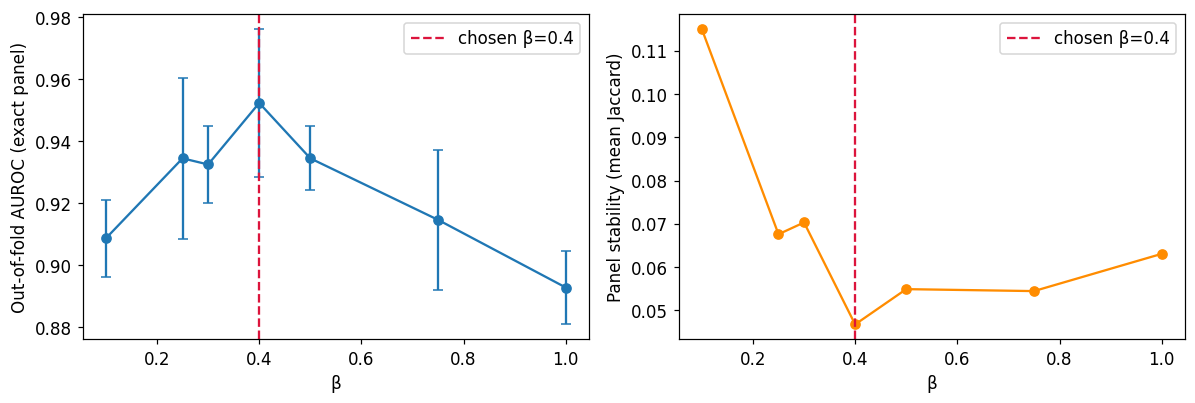

α=1.0  β=0.4  λ₀=10.0  checkpoints → checkpoints_a1.0_b0.4


In [19]:
# 6.1  Scoring classifier: same as make_classifier() in the organisers' panel_checker.py
def make_classifier():
    return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000, random_state=0))

def score_panel(Xtr_panel, ytr, Xte_panel, seed=SEED):
    return make_classifier().fit(Xtr_panel, ytr).predict_proba(Xte_panel)[:, 1]


# 6.0  Beta selection by nested CV
if AUTO_BETA:
    t0 = time.perf_counter()
    preds = {b: {r: ([], []) for r in range(N_OUTER_REPEATS)} for b in BETA_GRID}; panels = {b: [] for b in BETA_GRID}
    for rep in range(N_OUTER_REPEATS):
        for tr, va in outer_splits(rep, offset=1000):
            sl, _ = select_shortlist(Xn[tr], y[tr], lib_raw[tr], SEED, INNER_REPEATS)          # training rows only
            rel, red = qubo_inputs(Xn[tr][:, sl], y[tr]); bits, sizes = get_bits(len(sl))
            vi = np.where(sizes == K)[0]; Bv = bits[vi]
            for b in BETA_GRID:
                Q = qubo_objective_matrix(rel, red, ALPHA, b)               # λ not needed: we only search size-K panels
                g = sl[np.where(bits[vi[np.argmin(((Bv @ Q) * Bv).sum(axis=1))]])[0]]
                preds[b][rep][0].append(y[va]); preds[b][rep][1].append(score_panel(Xn[tr][:, g], y[tr], Xn[va][:, g]))
                panels[b].append(set(int(x) for x in g))
    rows_b = []
    for b in BETA_GRID:
        aucs = [roc_auc_score(np.concatenate(preds[b][r][0]), np.concatenate(preds[b][r][1])) for r in range(N_OUTER_REPEATS)]
        pj = [len(p) and len(p & q) / len(p | q) for i, p in enumerate(panels[b]) for q in panels[b][i + 1:]]
        rows_b.append(dict(beta=b, auroc_mean=np.mean(aucs), auroc_sd=(np.std(aucs, ddof=1) if len(aucs) > 1 else 0.0), panel_jaccard=np.mean(pj)))
    beta_table = pd.DataFrame(rows_b)
    best = beta_table.loc[beta_table.auroc_mean.idxmax()]
    BETA_FLOOR = 0.2          # below this the redundancy term is too weak to be a real QUBO trade-off
    cand = beta_table[(beta_table.auroc_mean >= best.auroc_mean - best.auroc_sd) & (beta_table.beta >= BETA_FLOOR)]
    BETA = float(cand.sort_values(['auroc_mean', 'panel_jaccard'], ascending=False).iloc[0].beta)
    beta_table['chosen'] = beta_table.beta == BETA
    display(beta_table.round(3))
    print(f"Chosen β = {BETA}  (best AUROC {best.auroc_mean:.3f} at β={best.beta}; {len(cand)} β values within 1 SD; most stable of those)  [{time.perf_counter()-t0:.0f}s]")
    print()

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].errorbar(beta_table.beta, beta_table.auroc_mean, yerr=beta_table.auroc_sd, marker='o', capsize=3); ax[0].set_ylabel('Out-of-fold AUROC (exact panel)')
    ax[1].plot(beta_table.beta, beta_table.panel_jaccard, marker='o', color='darkorange'); ax[1].set_ylabel('Panel stability (mean Jaccard)')
    for a_ in ax: a_.axvline(BETA, color='crimson', ls='--', label=f'chosen β={BETA}'); a_.set_xlabel('β'); a_.legend()
    plt.tight_layout(); plt.show()
else:
    beta_table = pd.DataFrame([dict(beta=BETA, chosen=True)]); print(f"AUTO_BETA off: using β = {BETA}")

# from here on everything uses the chosen beta
CKPT_DIR = Path(f"checkpoints_a{ALPHA}_b{BETA}"); CKPT_DIR.mkdir(exist_ok=True)
print(f"α={ALPHA}  β={BETA}  λ₀={LAMBDA0}  checkpoints → {CKPT_DIR}")

In [20]:
# Nested CV at the chosen beta
def run_outer_fold(rep, fold, tr, va):
    ck = CKPT_DIR / f"outer_r{rep}_f{fold}.pkl"
    if ck.exists():
        return pickle.load(open(ck, 'rb'))
    pk = run_pipeline(tr, f"r{rep}f{fold}", INNER_REPEATS, QAOA_REPS_OUTER)
    cache = {}
    for r in pk['rows']:
        r.update(rep=rep, fold=fold, va=va, has_prob=False, prob=None)
        if r['panel'] is not None:                         # score on VALIDATION patients only
            if r['panel'] not in cache:
                g = list(r['panel'])
                cache[r['panel']] = score_panel(Xn[tr][:, g], y[tr], Xn[va][:, g])
            r['prob'] = cache[r['panel']]; r['has_prob'] = True
    out = dict(rows=pk['rows'], n=pk['n'], lam=pk['lam'], t_short=pk['t_short'])
    pickle.dump(out, open(ck, 'wb'))
    return out

t_all = time.perf_counter(); outer_results = []
for rep in range(N_OUTER_REPEATS):
    for fold, (tr, va) in enumerate(outer_splits(rep)):
        t0 = time.perf_counter()
        out = run_outer_fold(rep, fold, tr, va); outer_results.append(out)
        print(f"  repeat {rep} fold {fold}: shortlist={out['n']} genes, λ={out['lam']:.0f}, "
              f"funnel {out['t_short']:.1f}s, fold total {time.perf_counter()-t0:.1f}s")
print(f"\nNested CV finished in {time.perf_counter()-t_all:.0f}s")

outer_df = pd.DataFrame([r for o in outer_results for r in o['rows']])

  repeat 0 fold 0: shortlist=12 genes, λ=10, funnel 3.1s, fold total 12.8s
  repeat 0 fold 1: shortlist=12 genes, λ=10, funnel 2.9s, fold total 13.2s
  repeat 0 fold 2: shortlist=16 genes, λ=10, funnel 2.2s, fold total 41.8s
  repeat 0 fold 3: shortlist=12 genes, λ=10, funnel 2.2s, fold total 16.3s
  repeat 0 fold 4: shortlist=12 genes, λ=10, funnel 3.0s, fold total 12.8s
  repeat 1 fold 0: shortlist=12 genes, λ=10, funnel 2.8s, fold total 13.3s
  repeat 1 fold 1: shortlist=12 genes, λ=10, funnel 2.0s, fold total 13.4s
  repeat 1 fold 2: shortlist=12 genes, λ=10, funnel 1.7s, fold total 12.7s
  repeat 1 fold 3: shortlist=13 genes, λ=10, funnel 1.7s, fold total 14.8s
  repeat 1 fold 4: shortlist=12 genes, λ=10, funnel 2.2s, fold total 12.6s
  repeat 2 fold 0: shortlist=12 genes, λ=10, funnel 1.7s, fold total 13.3s
  repeat 2 fold 1: shortlist=12 genes, λ=10, funnel 1.8s, fold total 13.3s
  repeat 2 fold 2: shortlist=16 genes, λ=10, funnel 1.7s, fold total 36.9s
  repeat 2 fold 3: shortl

In [21]:
# 6.2  Pooled out-of-fold AUROC per (method, seed, repeat)
def pooled_auroc(df):
    recs, roc = [], []
    for (m, s, rep), g in df[df.has_prob].groupby(['method', 'seed', 'rep']):
        if g.fold.nunique() < N_OUTER_SPLITS: continue
        yt = np.concatenate([y[v] for v in g.va]); pr = np.concatenate(g.prob.values)
        recs.append(dict(method=m, seed=s, rep=rep, auroc=roc_auc_score(yt, pr))); roc.append((m, s, rep, yt, pr))
    return pd.DataFrame(recs), roc

auc_df, roc_store = pooled_auroc(outer_df)
METHOD_ORDER = ['Exact (QUBO)', 'QAOA p=2', 'SA @circuits', 'SA @shots', 'Random search @circuits', 'Random search @shots',
                'Top-4 AUROC', 'LASSO', 'RFE (LogReg)', 'Random Forest', 'Greedy mRMR', 'Random 4-gene panel']
METHOD_ORDER = [m for m in METHOD_ORDER if m in set(outer_df.method)]

outer_df['right_size'] = outer_df.raw_size == K
outer_df['gap'] = outer_df.energy - outer_df.opt_energy
disc = outer_df.groupby('method').agg(runs=('is_opt', 'size'), found_best_pct=('is_opt', lambda s: 100 * s.mean()),
                                      right_size_pct=('right_size', lambda s: 100 * s.mean()),
                                      median_pct_rank=('pct_rank', 'median'), mean_energy_gap=('gap', 'mean'))
aucs = auc_df.groupby('method').auroc.agg(AUROC_mean='mean', AUROC_sd='std', n_runs='count')
summary = disc.join(aucs).loc[METHOD_ORDER]

print("Leakage-free nested-CV results (validation patients only). "
      f"{N_OUTER_SPLITS}-fold × {N_OUTER_REPEATS} repeats × seeds where stochastic.")
print("found_best_pct = % of (fold×seed×repeat) runs whose output equals the exact QUBO optimum;")
print("right_size_pct = % of runs whose raw output has exactly 4 genes;")
print("median_pct_rank = fraction of all size-4 panels that score as well or better (0.5 = random guessing, ~0 = optimum).\n")
display(summary.round(3))

Leakage-free nested-CV results (validation patients only). 5-fold × 3 repeats × seeds where stochastic.
found_best_pct = % of (fold×seed×repeat) runs whose output equals the exact QUBO optimum;
right_size_pct = % of runs whose raw output has exactly 4 genes;
median_pct_rank = fraction of all size-4 panels that score as well or better (0.5 = random guessing, ~0 = optimum).



,runs,found_best_pct,right_size_pct,median_pct_rank,mean_energy_gap,AUROC_mean,AUROC_sd,n_runs
method,,,,,,,,
Exact (QUBO),15,100.000,100.0,0.002,0.000,0.863,0.084,3
QAOA p=2,75,28.000,100.0,0.005,0.027,0.876,0.049,15
SA @circuits,75,1.333,100.0,0.075,0.106,0.928,0.039,15
SA @shots,75,100.000,100.0,0.002,0.000,0.863,0.071,15
Random search @circuits,75,2.667,100.0,0.059,0.105,0.918,0.037,15
Random search @shots,75,94.667,100.0,0.002,0.000,0.872,0.066,15
Top-4 AUROC,15,0.000,100.0,0.609,0.240,0.901,0.060,3
LASSO,75,21.333,100.0,0.008,0.047,0.869,0.036,15
RFE (LogReg),15,0.000,100.0,0.036,0.105,0.897,0.025,3


### Sensitivity, specificity and balanced accuracy
Pooled out-of-fold predictions thresholded at 0.5, averaged over seeds and repeats. AUROC is threshold-free; these numbers show how the classifier behaves at its default cut-off.

In [22]:
# 6.2b  Sensitivity, specificity, balanced accuracy (pooled out-of-fold, threshold 0.5)
def threshold_metrics(yt, pr, thr=0.5):
    pred = (pr >= thr).astype(int)
    sens = ((pred == 1) & (yt == 1)).sum() / (yt == 1).sum()
    spec = ((pred == 0) & (yt == 0)).sum() / (yt == 0).sum()
    return sens, spec, (sens + spec) / 2

cls_df = pd.DataFrame([dict(method=m, **dict(zip(['sensitivity', 'specificity', 'balanced_acc'], threshold_metrics(yt, pr))))
                       for (m, s, rep, yt, pr) in roc_store])
display(cls_df.groupby('method').mean().reindex(METHOD_ORDER).round(3))

,sensitivity,specificity,balanced_acc
method,,,
Exact (QUBO),0.857,0.722,0.790
QAOA p=2,0.829,0.706,0.767
SA @circuits,0.862,0.822,0.842
SA @shots,0.857,0.722,0.790
Random search @circuits,0.857,0.783,0.820
Random search @shots,0.857,0.744,0.801
Top-4 AUROC,0.810,0.806,0.808
LASSO,0.786,0.767,0.776
RFE (LogReg),0.810,0.833,0.821


In [23]:
# 6.3  QAOA statistics vs random guessing
q = outer_df[outer_df.method == QAOA_MAIN]
print(f"{QAOA_MAIN}: {len(q)} runs  ({q.fold.nunique()} folds × {q.rep.nunique()} repeats × {q.seed.nunique()} seeds)")
print(f"  found exact optimum : {q.is_opt.mean():.1%}")
print(f"  wrong-size output   : {(~q.right_size).mean():.1%}")
print(f"  mean prob. mass on size-4 bitstrings : {q.frac_valid.mean():.1%}   (random bitstring: {comb(MAX_SHORTLIST,K)/2**MAX_SHORTLIST:.1%} at n={MAX_SHORTLIST})")
print(f"  mean prob. mass on the optimum       : {q.p_opt.mean():.3%}   (random: {1/2**MAX_SHORTLIST:.4%} at n={MAX_SHORTLIST})")
print(f"  median percentile rank of QAOA panel: {q.pct_rank.median():.3f}   (random panel: 0.5)")
rs = outer_df[outer_df.method == 'Random search @circuits']
print(f"  random search with the SAME number of circuit runs: found optimum {rs.is_opt.mean():.1%}, wrong-size {(~rs.right_size).mean():.1%}")

QAOA p=2: 75 runs  (5 folds × 3 repeats × 5 seeds)
  found exact optimum : 28.0%
  wrong-size output   : 0.0%
  mean prob. mass on size-4 bitstrings : 24.5%   (random bitstring: 2.8% at n=16)
  mean prob. mass on the optimum       : 0.036%   (random: 0.0015% at n=16)
  median percentile rank of QAOA panel: 0.005   (random panel: 0.5)
  random search with the SAME number of circuit runs: found optimum 2.7%, wrong-size 0.0%


### 6.4 ROC curves (out-of-fold, mean over seeds and repeats)
Six methods are shown: exact QUBO, QAOA, LASSO, top-4 AUROC, Random Forest and a random panel. The other methods are in the appendix.

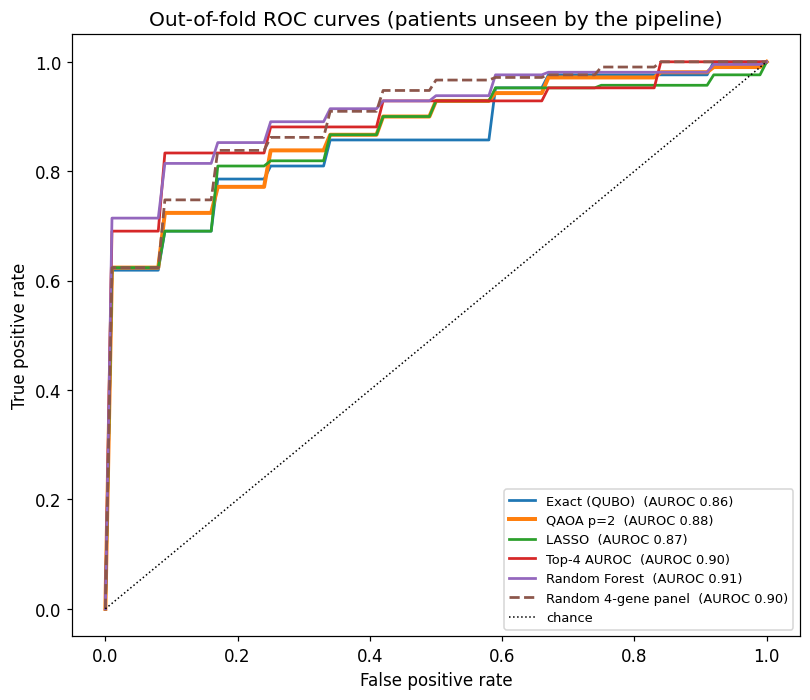

In [24]:
fpr_grid = np.linspace(0, 1, 101)
ROC_METHODS = [m for m in ['Exact (QUBO)', QAOA_MAIN, 'LASSO', 'Top-4 AUROC', 'Random Forest', 'Random 4-gene panel'] if m in set(auc_df.method)]
palette = dict(zip(ROC_METHODS, sns.color_palette('tab10', len(ROC_METHODS))))
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for m in ROC_METHODS:
    tprs = []
    for (mm, s, rep, yt, pr) in roc_store:
        if mm != m: continue
        fpr, tpr, _ = roc_curve(yt, pr); tprs.append(np.interp(fpr_grid, fpr, tpr))
    mean_tpr = np.mean(tprs, axis=0); mean_tpr[0] = 0
    a = summary.loc[m, 'AUROC_mean']
    ax.plot(fpr_grid, mean_tpr, lw=2.6 if m == QAOA_MAIN else 1.8, color=palette[m],
            ls='--' if m == 'Random 4-gene panel' else '-', label=f"{m}  (AUROC {a:.2f})")
ax.plot([0, 1], [0, 1], 'k:', lw=1, label='chance')
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
ax.set_title('Out-of-fold ROC curves (patients unseen by the pipeline)'); ax.legend(fontsize=8.5, loc='lower right')
plt.tight_layout(); plt.show()

### 6.5 Runtime and compute budget
QAOA uses `QAOA_MAXITER + 1` circuit executions of `QAOA_SHOTS` shots each. SA and random search appear at both the circuit-matched and the shot-matched budget. Runtimes cover the solver only; the shortlist and QUBO construction are shared by all methods and reported separately.

,runtime_s,circuit_runs,shots,bitstring_evals
method,,,,
Exact (QUBO),0.0002,0.0,0.0,686.3333
QAOA p=2,1.9512,47.8,48947.2,48947.2000
SA @circuits,0.0009,0.0,0.0,101.0000
SA @shots,0.4541,0.0,0.0,103424.0000
Random search @circuits,0.0001,0.0,0.0,101.0000
Random search @shots,0.0021,0.0,0.0,103424.0000
Top-4 AUROC,0.0005,0.0,0.0,NaN
LASSO,0.0931,0.0,0.0,NaN
RFE (LogReg),0.1278,0.0,0.0,NaN


Shared preprocessing per outer fold (funnel): mean 2.1s — identical for all methods.


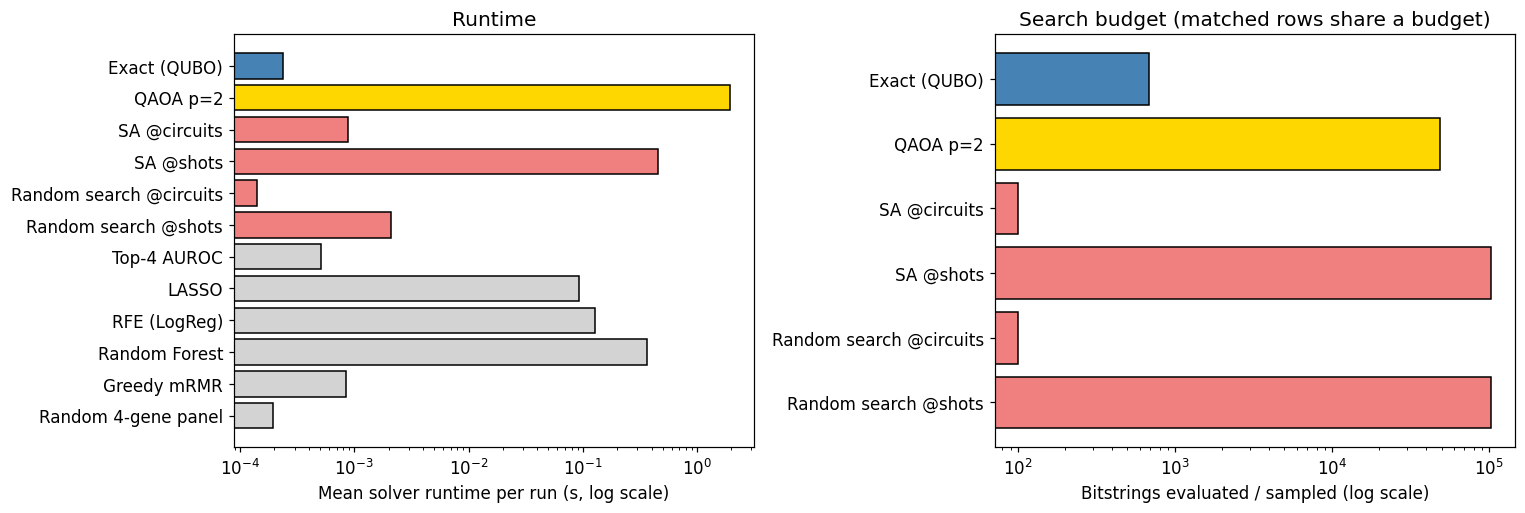

In [25]:
bud = outer_df.groupby('method').agg(runtime_s=('runtime', 'mean'), circuit_runs=('circuits', 'mean'),
                                     shots=('shots', 'mean'), bitstring_evals=('evals', 'mean')).loc[METHOD_ORDER]
display(bud.round(4))
print(f"Shared preprocessing per outer fold (funnel): mean {np.mean([o['t_short'] for o in outer_results]):.1f}s — identical for all methods.")

col = lambda m: 'gold' if m.startswith('QAOA') else 'steelblue' if m.startswith('Exact') else 'lightcoral' if ('SA' in m or 'Random search' in m) else 'lightgrey'
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].barh(bud.index, bud.runtime_s, color=[col(m) for m in bud.index], edgecolor='k'); ax[0].set_xscale('log')
ax[0].invert_yaxis(); ax[0].set_xlabel('Mean solver runtime per run (s, log scale)'); ax[0].set_title('Runtime')
b = bud.dropna(subset=['bitstring_evals'])
ax[1].barh(b.index, b.bitstring_evals, color=[col(m) for m in b.index], edgecolor='k'); ax[1].set_xscale('log')
ax[1].invert_yaxis(); ax[1].set_xlabel('Bitstrings evaluated / sampled (log scale)'); ax[1].set_title('Search budget (matched rows share a budget)')
plt.tight_layout(); plt.show()

---
## Phase 7 — Final run on the full team pool
The same pipeline is run once on all 26 patients, with QAOA over all depths and seeds. Nothing from this run is reported as a validation result; the organisers' hidden test patients are the held-out set.

**Final panel.** We report the Random Forest selection on the shortlist as our final panel. In the nested CV it gave a strong and balanced result (AUROC, sensitivity and specificity in 6.2 and 6.2b), and the other methods' panels share most of its genes. The differences between methods are small compared with the fold-to-fold variation, so the choice is made on balance and agreement between methods, not on a single best score. The QUBO and QAOA panels are reported alongside it.

In [26]:
# 7.1  Full-pool pipeline
ck = CKPT_DIR / "final.pkl"
if ck.exists():
    final = pickle.load(open(ck, 'rb'))
else:
    final = run_pipeline(np.arange(len(y)), 'final', INNER_REPEATS_FINAL, QAOA_REPS_FINAL)
    pickle.dump(final, open(ck, 'wb'))

final_df = pd.DataFrame(final['rows'])
SL = final['shortlist']; n_sl = final['n']; SL_NAMES = gene_names[SL]
print(f"Shortlist: {n_sl} genes | λ = {final['lam']:.0f} (verified over all 2^{n_sl} bitstrings) | funnel {final['t_short']:.1f}s")
display(pd.DataFrame({'gene': SL_NAMES, 'stability': final['freq'][SL].round(2),
                      'relevance |corr(y)|': final['rel'].round(3), 'AUROC': auroc_vec(Xn[:, SL], y).round(3)}))

Shortlist: 16 genes | λ = 10 (verified over all 2^16 bitstrings) | funnel 4.8s


,gene,stability,relevance |corr(y)|,AUROC
0,FGFRL1,0.89,0.808,1.000
1,CLCA4,0.89,0.724,0.988
2,AGPAT1,0.77,0.712,0.976
3,LIMCH1,0.71,0.762,0.976
4,DPY19L1,0.70,0.807,0.994
5,EPDR1,0.68,0.764,0.976
6,HNRNPUL1,0.66,0.724,0.970
7,LRRC28,0.65,0.722,0.964
8,DNASE1L3,0.64,0.854,0.988
9,AC009237.3,0.61,0.808,0.970


### 7.1b Funnel summary
Number of genes left after each stage, from the raw matrix to the final shortlist. Stages 3–6 are a single pass on all 26 patients, for display only; the shortlists used in the CV come from the fold-wise funnel.

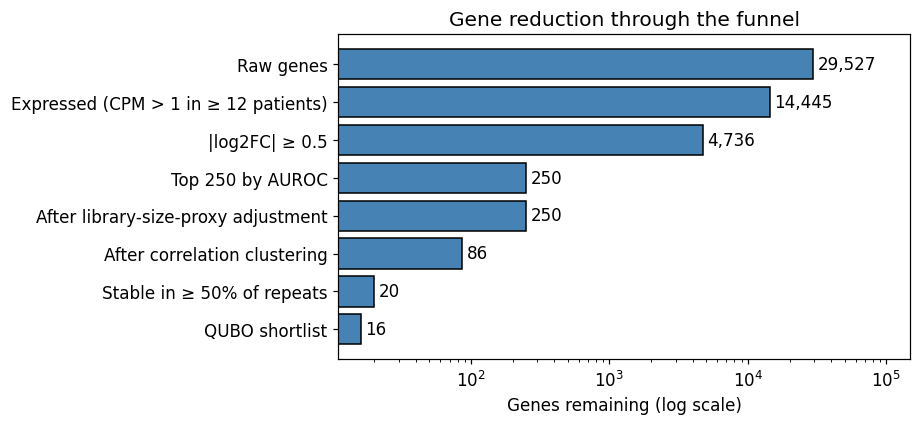

In [27]:
# 7.1b  Funnel counts on the full pool (one pass, descriptive)
a_f = auroc_vec(Xn, y); l_f = lfc_vec(Xn, y)
cand_f = np.where(l_f >= MIN_LFC)[0]; n_lfc = len(cand_f)
cand_f = cand_f[np.argsort(-a_f[cand_f], kind='stable')][:TOP_N_RELEVANCE]
ll_f = np.log2(lib_raw + 1); llc_f = ll_f - ll_f.mean()
Xc_f = Xn[:, cand_f] - Xn[:, cand_f].mean(axis=0)
slope_f = (llc_f @ Xc_f) / float(llc_f @ llc_f)
keep_f = cand_f[auroc_vec(Xc_f - np.outer(llc_f, slope_f), y) >= 0.6]
if len(keep_f) < 8: keep_f = cand_f[:50]
C_f = np.abs(np.nan_to_num(np.corrcoef(Xn[:, keep_f].T)))
D_f = np.clip(1 - C_f, 0, None); np.fill_diagonal(D_f, 0); D_f = (D_f + D_f.T) / 2
cl_f = fcluster(linkage(squareform(D_f, checks=False), method='average'), t=1 - CORR_THRESHOLD, criterion='distance')
n_rep = sum(min(int((cl_f == c).sum()), GENES_PER_CLUSTER) for c in np.unique(cl_f))
stages = [('Raw genes', X_raw.shape[1]), ('Expressed (CPM > 1 in ≥ 12 patients)', Xn.shape[1]), (f'|log2FC| ≥ {MIN_LFC}', n_lfc),
          (f'Top {TOP_N_RELEVANCE} by AUROC', len(cand_f)), ('After library-size-proxy adjustment', len(keep_f)),
          ('After correlation clustering', n_rep), ('Stable in ≥ 50% of repeats', int((final['freq'] >= STABILITY_THRESHOLD).sum())),
          ('QUBO shortlist', n_sl)]
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.barh([s_[0] for s_ in stages], [s_[1] for s_ in stages], color='steelblue', edgecolor='k')
ax.set_xscale('log'); ax.invert_yaxis(); ax.set_xlim(right=max(s_[1] for s_ in stages) * 5)
for i_, s_ in enumerate(stages): ax.text(s_[1] * 1.08, i_, f'{s_[1]:,}', va='center')
ax.set_xlabel('Genes remaining (log scale)'); ax.set_title('Gene reduction through the funnel')
plt.tight_layout(); plt.show()

### 7.2 Q-matrix heatmap and relevance vs redundancy
Left: the mRMR part of the QUBO (diagonal = −α·relevance, off-diagonal = β·redundancy; the constant λ terms are left out so the biology stays visible). Right: each shortlist gene by relevance and mean redundancy, with the exact, QAOA and final (Random Forest) panels marked. The final panel is outlined in green on the matrix. A good panel sits high and to the left.

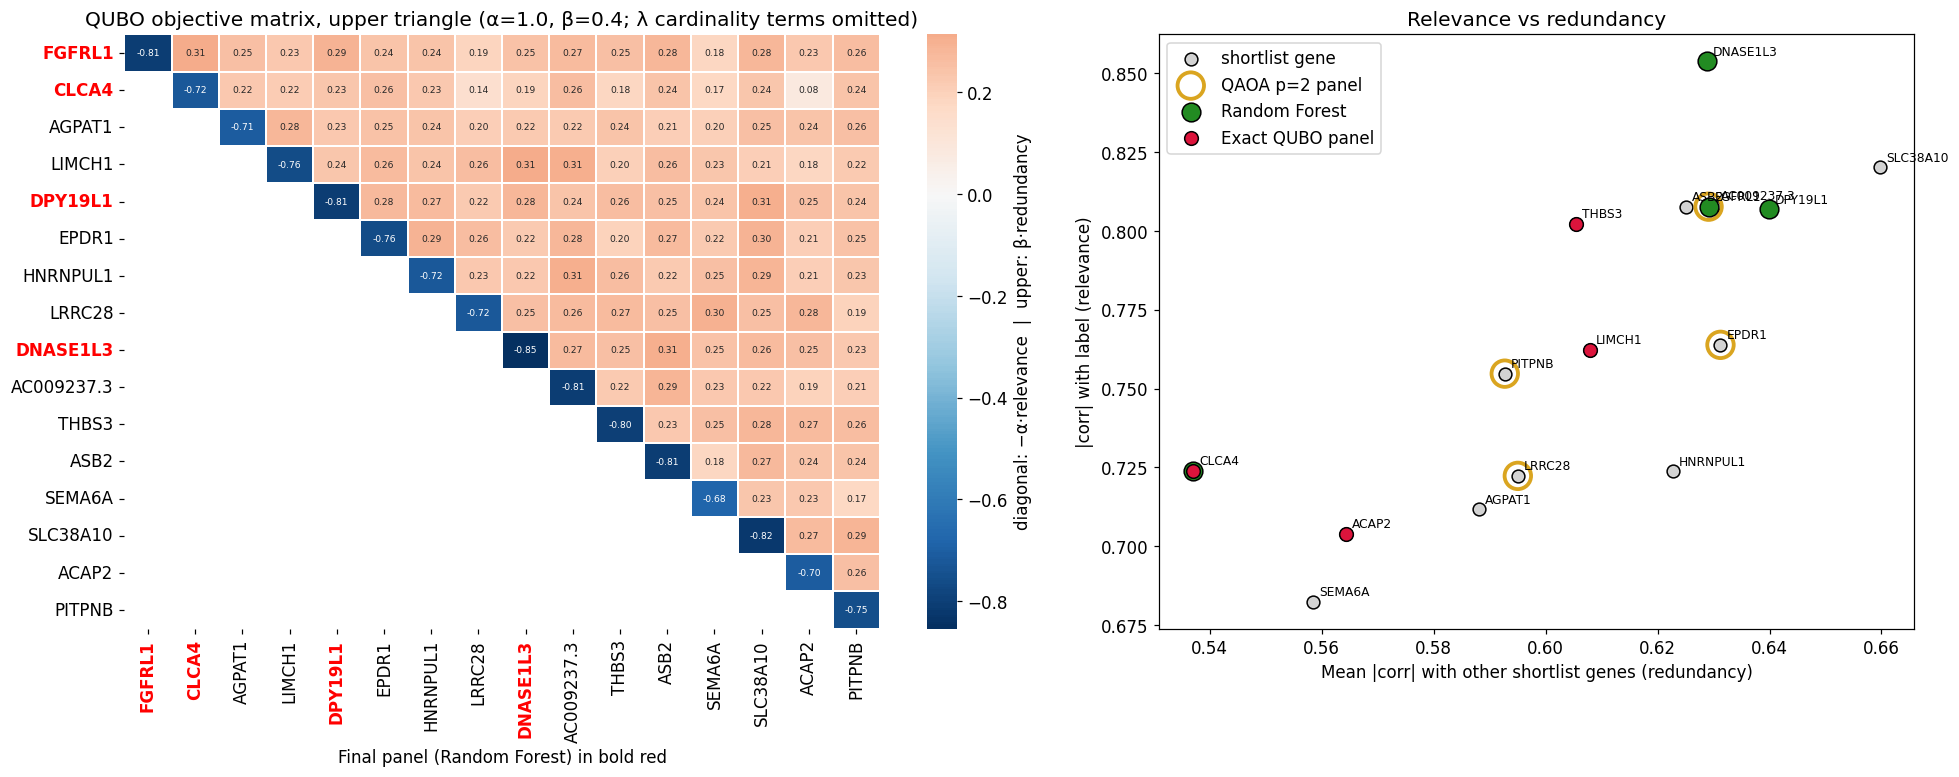

Random Forest panel : ['CLCA4', 'DNASE1L3', 'DPY19L1', 'FGFRL1']
Exact panel : ['CLCA4', 'LIMCH1', 'THBS3', 'ACAP2']
QAOA p=2 panel: ['FGFRL1', 'EPDR1', 'LRRC28', 'PITPNB']


In [28]:
def modal_panel(rows_df, method):
    ps = [p for p in rows_df[rows_df.method == method].panel if p is not None]
    return Counter(ps).most_common(1)[0][0] if ps else None

C_sl, rel_sl = final['C'], final['rel']             # C_sl: symmetric redundancy (diag 0)
M_obj = qubo_objective_matrix(rel_sl, final['red'], ALPHA, BETA)   # upper-triangular objective part of Q

exact_panel = modal_panel(final_df, 'Exact (QUBO)')
qaoa_final_name = QAOA_MAIN if (final_df.method == QAOA_MAIN).any() else final_df[final_df.method.str.startswith('QAOA')].method.iloc[0]
qaoa_panel  = modal_panel(final_df, qaoa_final_name)
pos = {int(g): i for i, g in enumerate(SL)}
ex_loc = {pos[g] for g in exact_panel}; qa_loc = {pos[g] for g in qaoa_panel}
rf_panel = modal_panel(final_df, 'Random Forest')                  # final panel
rf_loc = sorted(pos[g] for g in rf_panel); rf_names = set(gene_names[list(rf_panel)])

fig, axes = plt.subplots(1, 2, figsize=(18, 7.2), gridspec_kw={'width_ratios': [1.25, 1]})
mask_lower = np.tril(np.ones((n_sl, n_sl), dtype=bool), k=-1)       # hide the (empty) lower triangle
sns.heatmap(M_obj, mask=mask_lower, ax=axes[0], cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size': 6},
            xticklabels=SL_NAMES, yticklabels=SL_NAMES, linewidths=.3, cbar_kws={'label': 'diagonal: −α·relevance  |  upper: β·redundancy'})
axes[0].set_title(f'QUBO objective matrix, upper triangle (α={ALPHA}, β={BETA}; λ cardinality terms omitted)')
_exact_names = set(gene_names[list(exact_panel)])
for labs in (axes[0].get_xticklabels(), axes[0].get_yticklabels()):
    for lab in labs:
        if lab.get_text() in rf_names: lab.set_fontweight('bold'); lab.set_color('red')
axes[0].set_xlabel('Final panel (Random Forest) in bold red')

mean_red = (C_sl.sum(axis=1) - np.diag(C_sl)) / (n_sl - 1)
ax = axes[1]
ax.scatter(mean_red, rel_sl, s=70, c='lightgrey', edgecolors='k', label='shortlist gene')
ax.scatter(mean_red[list(qa_loc)], rel_sl[list(qa_loc)], s=300, facecolors='none', edgecolors='goldenrod', linewidths=2.5, label=f'{qaoa_final_name} panel')
ax.scatter(mean_red[rf_loc], rel_sl[rf_loc], s=150,  c='forestgreen', edgecolors='k', label='Random Forest')
ax.scatter(mean_red[list(ex_loc)], rel_sl[list(ex_loc)], s=80, c='crimson', edgecolors='k', label='Exact QUBO panel')
for i, g in enumerate(SL_NAMES): ax.annotate(g, (mean_red[i], rel_sl[i]), fontsize=8, xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('Mean |corr| with other shortlist genes (redundancy)'); ax.set_ylabel('|corr| with label (relevance)')
ax.set_title('Relevance vs redundancy'); ax.legend()
plt.tight_layout(); plt.show()
print("Random Forest panel :", sorted(rf_names))
print("Exact panel :", [str(g) for g in gene_names[list(exact_panel)]])
print(f"{qaoa_final_name} panel:", list(gene_names[list(qaoa_panel)]))

### 7.2b QAOA circuit
The QAOA circuit (p = 1) for the first 6 genes of the mRMR part of the QUBO. A 6-qubit slice is drawn because the 16-qubit circuit is too wide to read.

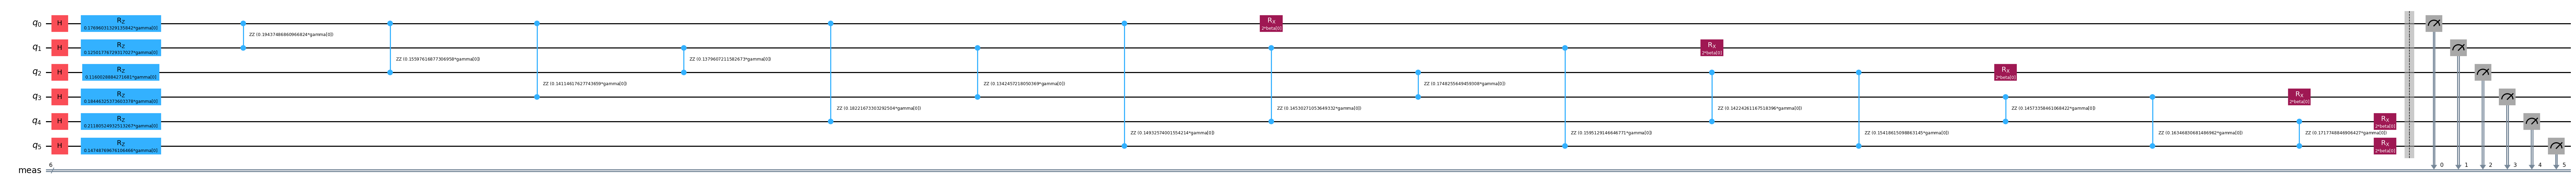

In [29]:
# 7.2b  Illustrative QAOA circuit (first 6 shortlist genes, p = 1)
Qd = M_obj[:6, :6]
qc_demo, _ = qaoa_circuit(Qd / np.abs(Qd).max(), 1)
display(qc_demo.draw('mpl', fold=0))

### 7.2c β sweep (full pool, exact optimum)
Descriptive only: it uses the full pool, so it says nothing about validation performance. Summarised in one line.

In [30]:
# 7.2c  β sweep: exact optimum of the full-pool QUBO (no λ needed: we search size-K panels only)
bits_f, sizes_f = get_bits(n_sl); vi_f = np.where(sizes_f == K)[0]; Bv_f = bits_f[vi_f]
red_up = np.triu(C_sl, 1); sweep = []
for b in sorted(set(BETA_GRID + [BETA, 2, 4])):
    e = ((Bv_f @ qubo_objective_matrix(rel_sl, red_up, ALPHA, b)) * Bv_f).sum(axis=1)
    loc = np.where(bits_f[vi_f[np.argmin(e)]])[0]
    sweep.append(dict(beta=b, panel=list(gene_names[SL[loc]]), mean_funnel_stability=round(float(final['freq'][SL[loc]].mean()), 2),
                      mean_relevance=round(float(rel_sl[loc].mean()), 3), mean_redundancy=round(float(np.mean([C_sl[i, j] for i in loc for j in loc if i < j])), 3),
                      overlap_with_current=len(set(gene_names[SL[loc]]) & _exact_names)))
sw = pd.DataFrame(sweep)
print(f"β sweep ({sw.beta.min()}–{sw.beta.max()}): {sw.panel.astype(str).nunique()} distinct exact panels; the exact optimum at the chosen β is recovered at {int((sw.overlap_with_current == K).sum())}/{len(sw)} β values")

β sweep (0.1–4.0): 5 distinct exact panels; the exact optimum at the chosen β is recovered at 5/9 β values


### 7.3 Panels found by each method (full pool)
For stochastic methods the modal panel across seeds is shown.

In [31]:
J_METHODS = [m for m in final_df.method.unique() if m != 'Random 4-gene panel'] + ['Random 4-gene panel']
J_METHODS = [m for m in J_METHODS if modal_panel(final_df, m) is not None]
panel_tab = pd.DataFrame([dict(method=m, panel=sorted(gene_names[list(modal_panel(final_df, m))])) for m in J_METHODS])
display(panel_tab)

,method,panel
0,Exact (QUBO),"[ACAP2, CLCA4, LIMCH1, THBS3]"
1,Top-4 AUROC,"[CLCA4, DNASE1L3, DPY19L1, FGFRL1]"
2,RFE (LogReg),"[AC009237.3, DNASE1L3, FGFRL1, THBS3]"
3,Greedy mRMR,"[AC009237.3, DNASE1L3, FGFRL1, THBS3]"
4,LASSO,"[AC009237.3, CLCA4, DNASE1L3, THBS3]"
5,Random Forest,"[CLCA4, DNASE1L3, DPY19L1, FGFRL1]"
6,SA @circuits,"[EPDR1, FGFRL1, SEMA6A, THBS3]"
7,Random search @circuits,"[CLCA4, DNASE1L3, HNRNPUL1, SLC38A10]"
8,SA @shots,"[ACAP2, CLCA4, LIMCH1, THBS3]"
9,Random search @shots,"[ACAP2, CLCA4, LIMCH1, THBS3]"


In [32]:
# 7.4  Full-pool QAOA results: depth × seed, with sampled panels and scores
qf = final_df[final_df.method.str.startswith('QAOA')].copy()
qf['right_size'] = qf.raw_size == K
_bits_f = get_bits(n_sl)[0]
qf['top_sampled_panels'] = qf.top_samples.apply(lambda ts: [(list(gene_names[SL[np.where(_bits_f[i])[0]]]), c) for i, c in ts])
qf['panel_genes'] = qf.panel.apply(lambda p: list(gene_names[list(p)]) if p is not None else None)
display(qf.groupby('method').agg(runs=('seed', 'size'), found_best_pct=('is_opt', lambda s: 100 * s.mean()),
                                 right_size_pct=('right_size', lambda s: 100 * s.mean()),
                                 mean_prob_size4=('frac_valid', 'mean'), mean_prob_optimum=('p_opt', 'mean'),
                                 mean_runtime_s=('runtime', 'mean'), circuits=('circuits', 'mean'), shots=('shots', 'mean')).round(4))
print("Sampled panels per run (top-5 by count) are exported in qaoa_fullpool_runs_with_samples.csv")

,runs,found_best_pct,right_size_pct,mean_prob_size4,mean_prob_optimum,mean_runtime_s,circuits,shots
method,,,,,,,,
QAOA p=1,5,20.0,100.0,0.2160,0.0002,3.0357,32.4,33177.6
QAOA p=2,5,20.0,100.0,0.1820,0.0002,5.0351,41.4,42393.6
QAOA p=3,5,0.0,100.0,0.1338,0.0000,12.9130,59.0,60416.0


Sampled panels per run (top-5 by count) are exported in qaoa_fullpool_runs_with_samples.csv


### 7.4b QAOA on IBM hardware (full pool, p = 3)
The hardware runs from Phase 5.2.1 (`ibm_marrakesh`, seeds 42, 256, 1024, 1024 shots per circuit) decoded back to gene names and compared with the exact optimum and with Aer at the same depth. `energy_rank` is the position of the panel among all C(16,4) = 1820 size-4 panels sorted by QUBO energy (1 = exact optimum). `auroc_in_sample` uses all 26 patients, so it is descriptive only. `wall_s` includes queue time.

Uniform random sampling over 16 qubits would give a valid fraction of C(16,4) / 2^16 = 2.8%. The figure shows the cost traces against two reference lines, the mean cost of uniform sampling and the cost of the exact optimum.

,seed,panel,shared_with_exact,energy_rank,gap_to_opt,frac_valid,p_opt,circuits,wall_s,auroc_in_sample
0,42,"[CLCA4, DNASE1L3, AC009237.3, ACAP2]",2,16,0.1904,0.0771,0.000,55,481.66,1.0
1,256,"[CLCA4, LIMCH1, DPY19L1, ACAP2]",3,13,0.1711,0.1523,0.000,54,1785.35,1.0
2,1024,"[CLCA4, LIMCH1, THBS3, ACAP2]",4,1,0.0000,0.0918,0.001,67,6154.81,1.0


Exact optimum: ['CLCA4', 'ACAP2', 'LIMCH1', 'THBS3']
Valid fraction, uniform random: 0.0278   Aer p=3: 0.1338   hardware: 0.1071
P(optimum), Aer p=3: 0.0000   hardware: 0.0003


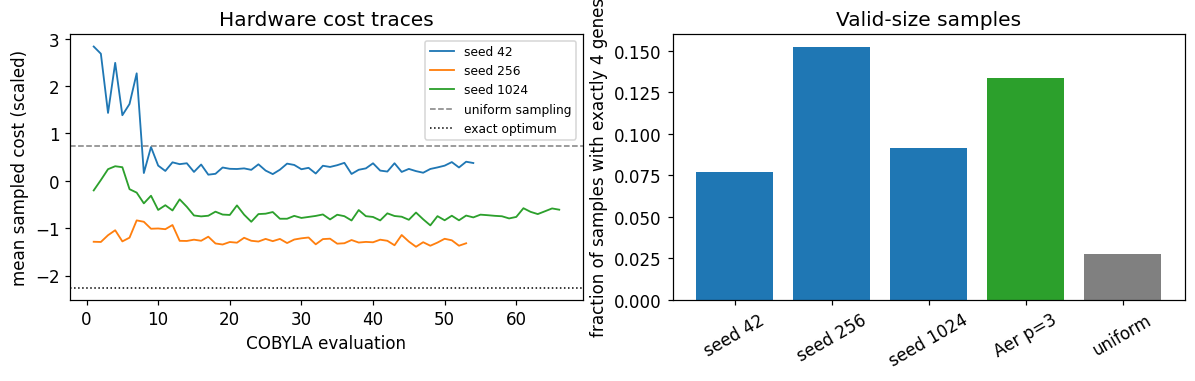

In [33]:
# 7.4b  Hardware runs vs exact optimum and Aer
# Restore the full-pool shortlist
sl, freq = select_shortlist(Xn, y, lib_raw, SEED, INNER_REPEATS_FINAL)   # same call as cell 23
assert len(sl) == N == 16, (len(sl), N)
assert len(valid_idx) == comb(N, K), (len(valid_idx), comb(N, K))        # catches clobbered valid_idx
assert len(ev) == len(valid_idx), (len(ev), len(valid_idx))              # catches clobbered ev

decode_hw = lambda st: tuple(int(sl[i]) for i in range(N) if (st >> i) & 1)    # bit i of the integer = qubit i = shortlist gene i
exact_panel = set(decode_hw(opt_idx))
pos_of = {int(v): i for i, v in enumerate(valid_idx)}

rows = []
for s, r in hw.items():
    if r['valid'] is None:
        rows.append(dict(seed=s, panel=None, frac_valid=r['frac_valid'], p_opt=r['p_opt'])); continue
    k = pos_of[r['valid']]; p = list(decode_hw(r['valid']))
    auc = roc_auc_score(y, score_panel(Xn[:, p], y, Xn[:, p]))
    rows.append(dict(seed=s, panel=list(gene_names[p]), shared_with_exact=len(exact_panel & set(p)),
                     energy_rank=int((ev < ev[k]).sum() + 1), gap_to_opt=round(float(ev[k] - ev.min()), 4),
                     frac_valid=r['frac_valid'], p_opt=r['p_opt'], circuits=len(r['trace']) + 1,
                     wall_s=r['runtime'], auroc_in_sample=round(auc, 3)))
hw_df = pd.DataFrame(rows); display(hw_df)
hw_df.to_csv('hardware_qaoa_runs.csv', index=False)
print("Exact optimum:", [str(g) for g in gene_names[list(exact_panel)]])

p_rand = comb(N, K) / 2 ** N
aer = final_df[final_df.method == f'QAOA p={HW_REPS}']
print(f"Valid fraction, uniform random: {p_rand:.4f}   Aer p={HW_REPS}: {aer.frac_valid.mean():.4f}   hardware: {np.mean([r['frac_valid'] for r in hw.values()]):.4f}")
print(f"P(optimum), Aer p={HW_REPS}: {aer.p_opt.mean():.4f}   hardware: {np.mean([r['p_opt'] for r in hw.values()]):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for s, r in hw.items():
    ax[0].plot(range(1, len(r['trace']) + 1), r['trace'], lw=1.2, label=f"seed {s}")
ax[0].axhline(cost_s.mean(), color='grey', ls='--', lw=1, label='uniform sampling')
ax[0].axhline(cost_s[opt_idx], color='k', ls=':', lw=1, label='exact optimum')
ax[0].set_xlabel('COBYLA evaluation'); ax[0].set_ylabel('mean sampled cost (scaled)'); ax[0].set_title('Hardware cost traces'); ax[0].legend(fontsize=8)
names = [f"seed {s}" for s in hw] + [f'Aer p={HW_REPS}', 'uniform']
vals = [r['frac_valid'] for r in hw.values()] + [aer.frac_valid.mean(), p_rand]
ax[1].bar(names, vals, color=['C0'] * len(hw) + ['C2', 'grey'])
ax[1].set_ylabel('fraction of samples with exactly 4 genes'); ax[1].set_title('Valid-size samples'); ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig('hardware_qaoa.png', dpi=150); plt.show()


### Reading the hardware runs
The true optimum was sampled at most once in the final shot set; the probability was 0.0000, 0.0010 and 0.0000. The valid-size fraction (7.7%, 9.2% and 15.2%) is above the 2.8% expected from random sampling, so the circuit is doing something, but the most frequent bitstrings occur only 2 to 3 times in 1024 shots (8 times for the all-zero string in seed 256), which is close to what a near-uniform distribution gives. The cost trace of seed 256 is flat from the first evaluation, so the optimizer did not find a direction to improve in.

The reported panel is the lowest-energy size-4 string among the sampled ones. That step is classical, so a good panel here does not by itself show that the hardware solved the QUBO. No error mitigation was used. We ran three of the five seeds because of the available QPU time. The hardware run is a feasibility check; the final panel in Phase 9 comes from the exact solver.

---
## Phase 8 — Permutation test of the whole procedure
The labels are permuted and the entire nested procedure (funnel, QUBO, exact search, out-of-fold AUROC) is repeated on each permutation, so the null distribution includes the selection step. Fewer inner repeats are used to keep the runtime manageable.

Real nested AUROC (exact panel): 0.893 | permuted mean 0.466 ± 0.130 | p = 0.0196  (279s)


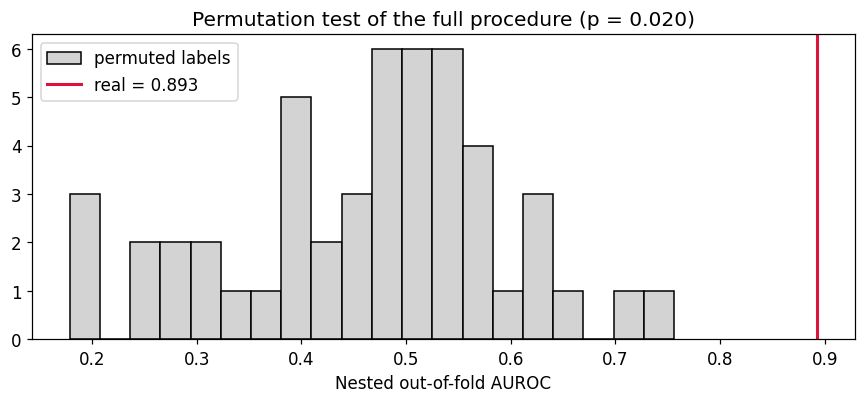

In [34]:
# 8.1  Permutation test of the whole nested procedure
PERM_INNER = 5
def nested_exact_auroc(yv, seed, inner_repeats=PERM_INNER):
    sg = StratifiedGroupKFold(n_splits=N_OUTER_SPLITS, shuffle=True, random_state=seed)
    yt, pr = [], []
    for tr, va in sg.split(Xn, yv, groups=patient_ids):
        sl, _ = select_shortlist(Xn[tr], yv[tr], lib_raw[tr], seed, inner_repeats)
        Xs = Xn[tr][:, sl]; rel, red = qubo_inputs(Xs, yv[tr]); bits, sizes = get_bits(len(sl))
        _, Q, cost = choose_lambda(rel, red, ALPHA, BETA, K, bits, sizes)
        vi = np.where(sizes == K)[0]; g = sl[np.where(bits[vi[np.argmin(cost[vi])]])[0]]
        pr.append(score_panel(Xn[tr][:, g], yv[tr], Xn[va][:, g])); yt.append(yv[va])
    return roc_auc_score(np.concatenate(yt), np.concatenate(pr))

if RUN_PERMUTATION:
    t0 = time.perf_counter()
    real_auc = nested_exact_auroc(y, SEED)
    rng_p = np.random.default_rng(SEED)
    perm_auc = np.array([nested_exact_auroc(rng_p.permutation(y), SEED + 1 + i) for i in range(N_PERMS)])
    p_val = (1 + (perm_auc >= real_auc).sum()) / (1 + N_PERMS)
    print(f"Real nested AUROC (exact panel): {real_auc:.3f} | permuted mean {perm_auc.mean():.3f} ± {perm_auc.std():.3f} | p = {p_val:.4f}  ({time.perf_counter()-t0:.0f}s)")
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.hist(perm_auc, bins=20, color='lightgrey', edgecolor='k', label='permuted labels'); ax.axvline(real_auc, color='crimson', lw=2, label=f'real = {real_auc:.3f}')
    ax.set_xlabel('Nested out-of-fold AUROC'); ax.set_title(f'Permutation test of the full procedure (p = {p_val:.3f})'); ax.legend(); plt.tight_layout(); plt.show()

---
## Phase 9 — Final Panel & Biological interpretation


═══ FINAL 4-GENE PANEL (Random Forest selection on the shortlist, full team pool) ═══


,gene,AUROC,abs_log2FC,direction,shortlist_stability
0,FGFRL1,1.000,1.68,↑ in LUAD,0.89
1,CLCA4,0.988,3.20,↓ in LUAD,0.89
2,DPY19L1,0.994,2.23,↑ in LUAD,0.70
3,DNASE1L3,0.988,2.33,↓ in LUAD,0.64


/tmp/ipykernel_1130/3578770420.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=d, x='label', y='expression', ax=axes[i], palette={'Normal': 'steelblue', 'LUAD': 'crimson'}, order=['Normal', 'LUAD'])
/tmp/ipykernel_1130/3578770420.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=d, x='label', y='expression', ax=axes[i], palette={'Normal': 'steelblue', 'LUAD': 'crimson'}, order=['Normal', 'LUAD'])
/tmp/ipykernel_1130/3578770420.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=d, x='label', y='expression', ax=axes[i]

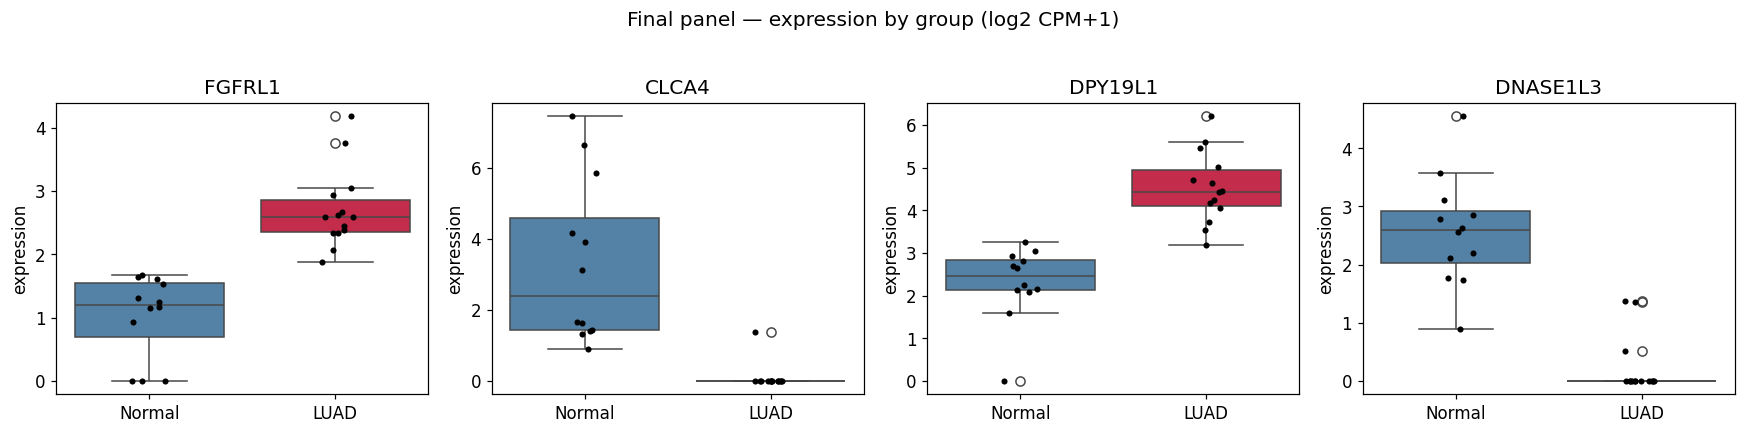

In [35]:
# 9.1  Final panel summary (descriptive statistics on the full pool; not a validation result)
FINAL_PANEL = list(gene_names[list(rf_panel)])
print("═══ FINAL 4-GENE PANEL (Random Forest selection on the shortlist, full team pool) ═══")
rows_ = []
for g in FINAL_PANEL:
    j = int(np.where(gene_names == g)[0][0]); r_ = np.corrcoef(Xn[:, j], y)[0, 1]
    rows_.append(dict(gene=g, AUROC=round(float(auroc_vec(Xn[:, [j]], y)[0]), 3), abs_log2FC=round(float(lfc_vec(Xn[:, [j]], y)[0]), 2),
                      direction='↑ in LUAD' if r_ > 0 else '↓ in LUAD', shortlist_stability=round(float(final['freq'][j]), 2)))
display(pd.DataFrame(rows_))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for i, g in enumerate(FINAL_PANEL):
    d = pd.DataFrame({'expression': X_norm[g].values, 'label': np.where(y == 1, 'LUAD', 'Normal')})
    sns.boxplot(data=d, x='label', y='expression', ax=axes[i], palette={'Normal': 'steelblue', 'LUAD': 'crimson'}, order=['Normal', 'LUAD'])
    sns.stripplot(data=d, x='label', y='expression', ax=axes[i], color='k', size=4, order=['Normal', 'LUAD'])
    axes[i].set_title(g); axes[i].set_xlabel('')
plt.suptitle('Final panel — expression by group (log2 CPM+1)', y=1.03); plt.tight_layout(); plt.show()

### 9.1b Final panel across patients
Expression of the four panel genes in all 26 patients (row z-scores), clustered, with colour bars for diagnosis (red = LUAD, blue = Normal), sex (orange = female, grey = male) and number of detected genes (viridis, dark = few).

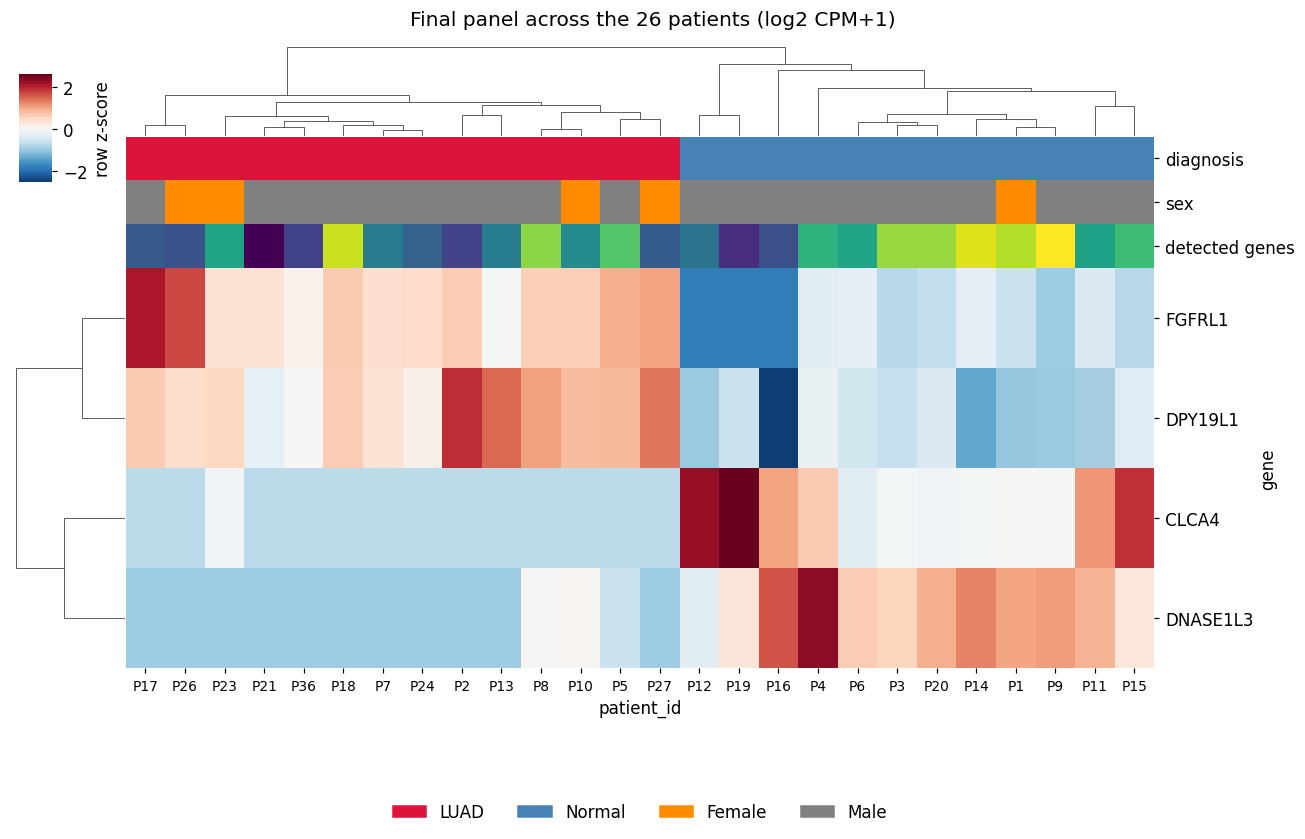

In [36]:
# 9.1b  Clustered heatmap of the final panel with patient annotations
from matplotlib.colors import to_hex
from matplotlib.patches import Patch
meta_i = meta.set_index('patient_id').loc[X_norm.index]
lib_n = (lib_raw - lib_raw.min()) / (lib_raw.max() - lib_raw.min())
col_df = pd.DataFrame({'diagnosis': ['crimson' if v == 1 else 'steelblue' for v in y],
                       'sex': ['darkorange' if s_ == 'female' else 'grey' for s_ in meta_i['sex']],
                       'detected genes': [to_hex(plt.cm.viridis(v)) for v in lib_n]}, index=X_norm.index)
cg = sns.clustermap(X_norm[FINAL_PANEL].T, z_score=0, cmap='RdBu_r', center=0, col_colors=col_df,
                    figsize=(12, 6.5), colors_ratio=0.07, dendrogram_ratio=(0.1, 0.15),
                    cbar_pos=(0.02, 0.78, 0.025, 0.15), cbar_kws={'label': 'row z-score'})
cg.ax_heatmap.set_xticklabels(cg.ax_heatmap.get_xticklabels(), fontsize=9)
cg.ax_heatmap.set_yticklabels(cg.ax_heatmap.get_yticklabels(), rotation=0, fontsize=11)
cg.ax_heatmap.legend(handles=[Patch(color='crimson', label='LUAD'), Patch(color='steelblue', label='Normal'),
                              Patch(color='darkorange', label='Female'), Patch(color='grey', label='Male')],
                     loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=4, frameon=False)
cg.fig.suptitle('Final panel across the 26 patients (log2 CPM+1)', y=1.02); plt.show()

In [37]:
# 9.2  Extension: panel stability across the outer training sets (no extra compute)
ex = outer_df[outer_df.method == 'Random Forest']
panels_by_split = [set(p) for p in ex.panel]
gene_freq = Counter(g for p in panels_by_split for g in p)
pair_j = [len(a & b) / len(a | b) for i, a in enumerate(panels_by_split) for b in panels_by_split[i + 1:]]
print(f"Random Forest panels from {len(panels_by_split)} runs (outer folds × seeds; each fold leaves ~20% of patients out).")
print(f"Mean pairwise Jaccard between those panels: {np.mean(pair_j):.2f}")
display(pd.DataFrame([(gene_names[g], c, f"{c/len(panels_by_split):.0%}") for g, c in gene_freq.most_common(10)], columns=['gene', 'count', 'frequency']))

# 9.3  Extension: sensitivity of the optimum to noise in relevance / redundancy
bits_f, sizes_f = get_bits(n_sl); vi = np.where(sizes_f == K)[0]; Bv = bits_f[vi]
red_f = np.triu(C_sl, 1); scale_noise = np.r_[rel_sl, red_f[np.triu_indices(n_sl, 1)]].mean()
clean_set = set(exact_panel); res_noise = []
for nl in [0.01, 0.05, 0.10, 0.20, 0.40]:
    ov = []
    for s in SEEDS:
        r_ = np.random.default_rng(s)
        Qn = build_qubo(np.abs(rel_sl + r_.normal(0, nl * scale_noise, n_sl)), np.triu(np.abs(red_f + r_.normal(0, nl * scale_noise, red_f.shape)), 1), ALPHA, BETA, final['lam'], K)
        best = vi[np.argmin(((Bv @ Qn) * Bv).sum(axis=1))]
        ov.append(len({int(SL[i]) for i in np.where(bits_f[best])[0]} & clean_set))
    res_noise.append(dict(noise_level=nl, mean_overlap_with_clean=np.mean(ov), min_overlap=min(ov)))
display(pd.DataFrame(res_noise))
print("Note: this perturbs the QUBO coefficients (parameter noise). Gate/readout noise on hardware-like QAOA would need an Aer NoiseModel — not done here.")

Random Forest panels from 75 runs (outer folds × seeds; each fold leaves ~20% of patients out).
Mean pairwise Jaccard between those panels: 0.10


,gene,count,frequency
0,FGFRL1,40,53%
1,EPDR1,15,20%
2,ACAP2,14,19%
3,AL049555.1,14,19%
4,DPY19L1,13,17%
5,AKR1B10,13,17%
6,CLCA4,12,16%
7,TSPAN17,10,13%
8,AGPAT1,9,12%
9,AC245041.2,8,11%


,noise_level,mean_overlap_with_clean,min_overlap
0,0.01,3.4,2
1,0.05,1.8,0
2,0.10,0.2,0
3,0.20,0.2,0
4,0.40,0.2,0


Note: this perturbs the QUBO coefficients (parameter noise). Gate/readout noise on hardware-like QAOA would need an Aer NoiseModel — not done here.


---
## Phase 10 — Outputs
Run log, result tables and the summary for submission.

In [38]:
# 10.1  Run log, exports, midpoint summary
for m, g in final_df.groupby('method'):
    log_result(m, f"qiskit {VERSIONS['qiskit']} + aer {VERSIONS['qiskit_aer']}" if m.startswith('QAOA') else 'numpy/scikit-learn',
               'seeds=' + ','.join(map(str, sorted(set(g.seed)))), f"alpha={ALPHA},beta={BETA},lambda={final['lam']},n={n_sl},k={K},maxiter={QAOA_MAXITER},shots={QAOA_SHOTS}",
               len(g), int(g.shots.sum()), g.runtime.mean(), list(gene_names[list(modal_panel(final_df, m))]) if modal_panel(final_df, m) else None)
display(pd.DataFrame(run_log))

pd.DataFrame({'gene': FINAL_PANEL}).to_csv('final_panel.csv', index=False)
drop_cols = ['va', 'prob', 'top_samples']
outer_df.drop(columns=[c for c in drop_cols if c in outer_df]).to_csv('outer_cv_all_runs.csv', index=False)
beta_table.to_csv('beta_selection.csv', index=False); summary.to_csv('outer_cv_summary.csv'); bud.to_csv('compute_budget.csv'); pd.DataFrame(run_log).to_csv('run_log.csv', index=False)
qf.drop(columns=['va', 'prob', 'top_samples'], errors='ignore').to_csv('qaoa_fullpool_runs_with_samples.csv', index=False)
with open('versions_and_seeds.txt', 'w') as f:
    f.write(f"versions: {VERSIONS}\nSEED={SEED}\nSEEDS={SEEDS}\nK={K}\nALPHA={ALPHA}\nBETA={BETA}\nLAMBDA0={LAMBDA0}\nQAOA_MAXITER={QAOA_MAXITER}\nQAOA_SHOTS={QAOA_SHOTS}\n"
            f"outer={N_OUTER_SPLITS}-fold x {N_OUTER_REPEATS}\ninner_repeats={INNER_REPEATS}/{INNER_REPEATS_FINAL}\n")
print("Saved: final_panel.csv, outer_cv_all_runs.csv, outer_cv_summary.csv, compute_budget.csv, run_log.csv, qaoa_fullpool_runs_with_samples.csv, versions_and_seeds.txt")


,method,library,seed,settings,runs,shots,runtime_s,panel
0,Exact (QUBO),numpy/scikit-learn,seeds=-1,"alpha=1.0,beta=0.4,lambda=10.0,n=16,k=4,maxite...",1,0,0.001,"[CLCA4, LIMCH1, THBS3, ACAP2]"
1,Greedy mRMR,numpy/scikit-learn,seeds=-1,"alpha=1.0,beta=0.4,lambda=10.0,n=16,k=4,maxite...",1,0,0.001,"[FGFRL1, DNASE1L3, AC009237.3, THBS3]"
2,LASSO,numpy/scikit-learn,"seeds=42,123,256,789,1024","alpha=1.0,beta=0.4,lambda=10.0,n=16,k=4,maxite...",5,0,0.102,"[CLCA4, DNASE1L3, AC009237.3, THBS3]"
3,QAOA p=1,qiskit 2.6.1 + aer 0.18.0,"seeds=42,123,256,789,1024","alpha=1.0,beta=0.4,lambda=10.0,n=16,k=4,maxite...",5,165888,3.036,"[CLCA4, EPDR1, DNASE1L3, SLC38A10]"
4,QAOA p=2,qiskit 2.6.1 + aer 0.18.0,"seeds=42,123,256,789,1024","alpha=1.0,beta=0.4,lambda=10.0,n=16,k=4,maxite...",5,211968,5.035,"[FGFRL1, EPDR1, LRRC28, PITPNB]"
5,QAOA p=3,qiskit 2.6.1 + aer 0.18.0,"seeds=42,123,256,789,1024","alpha=1.0,beta=0.4,lambda=10.0,n=16,k=4,maxite...",5,302080,12.913,"[CLCA4, DNASE1L3, THBS3, ACAP2]"
6,RFE (LogReg),numpy/scikit-learn,seeds=-1,"alpha=1.0,beta=0.4,lambda=10.0,n=16,k=4,maxite...",1,0,0.109,"[FGFRL1, DNASE1L3, AC009237.3, THBS3]"
7,Random 4-gene panel,numpy/scikit-learn,"seeds=42,123,256,789,1024","alpha=1.0,beta=0.4,lambda=10.0,n=16,k=4,maxite...",5,0,0.000,"[CLCA4, LRRC28, AC009237.3, THBS3]"
8,Random Forest,numpy/scikit-learn,"seeds=42,123,256,789,1024","alpha=1.0,beta=0.4,lambda=10.0,n=16,k=4,maxite...",5,0,0.369,"[FGFRL1, CLCA4, DPY19L1, DNASE1L3]"
9,Random search @circuits,numpy/scikit-learn,"seeds=42,123,256,789,1024","alpha=1.0,beta=0.4,lambda=10.0,n=16,k=4,maxite...",5,0,0.000,"[CLCA4, HNRNPUL1, DNASE1L3, SLC38A10]"


Saved: final_panel.csv, outer_cv_all_runs.csv, outer_cv_summary.csv, compute_budget.csv, run_log.csv, qaoa_fullpool_runs_with_samples.csv, versions_and_seeds.txt


In [39]:
P = list(FINAL_PANEL)
idx = [int(np.where(gene_names == g)[0][0]) for g in P]
tab = pd.DataFrame({'gene': P, 'AUROC': auroc_vec(Xn[:, idx], y).round(3), 'abs_log2FC': lfc_vec(Xn[:, idx], y).round(2),
                    'direction': ['↑ LUAD' if np.corrcoef(Xn[:, j], y)[0, 1] > 0 else '↓ LUAD' for j in idx]})
display(tab)
cm = pd.DataFrame(np.corrcoef(Xn[:, idx].T), index=P, columns=P).round(2)


,gene,AUROC,abs_log2FC,direction
0,FGFRL1,1.000,1.68,↑ LUAD
1,CLCA4,0.988,3.20,↓ LUAD
2,DPY19L1,0.994,2.23,↑ LUAD
3,DNASE1L3,0.988,2.33,↓ LUAD


In [40]:
display(cm)
print("Mean pairwise |corr|:", round(float(np.mean([abs(cm.iloc[i, j]) for i in range(4) for j in range(i+1, 4)])), 2))

,FGFRL1,CLCA4,DPY19L1,DNASE1L3
FGFRL1,1.00,-0.78,0.74,-0.62
CLCA4,-0.78,1.00,-0.59,0.47
DPY19L1,0.74,-0.59,1.00,-0.71
DNASE1L3,-0.62,0.47,-0.71,1.00


Mean pairwise |corr|: 0.65


In [41]:
print("\n" + "═" * 80 + "\n SUBMISSION SUMMARY\n" + "═" * 80)
print(f"Team: Gene42 — University of Birmingham Dubai | Track: Biology | Library: Qiskit {VERSIONS['qiskit']} (+ Aer {VERSIONS['qiskit_aer']})")
print(f"4-gene panel: {FINAL_PANEL}  (Random Forest selection on the shortlist, full team pool)")
print(f"Data split: patient-level nested CV, {N_OUTER_SPLITS}-fold × {N_OUTER_REPEATS} repeats; shortlist + QUBO + solvers re-run inside every training fold")
print(f"Shortlist (full pool): {n_sl} genes via stability selection ({INNER_SPLITS}-fold × {INNER_REPEATS_FINAL}); QUBO mRMR α={ALPHA}, β={BETA} (chosen by nested CV over {BETA_GRID}), λ={final['lam']:.0f}, k={K}")
print(f"QAOA: Aer shot-based simulator, COBYLA {QAOA_MAXITER} iters × {QAOA_SHOTS} shots, depths {QAOA_REPS_FINAL} (final) / {QAOA_REPS_OUTER} (CV), seeds {SEEDS}")
print(f"Out-of-fold AUROC (mean over seeds×repeats): " + ", ".join(f"{m} {summary.loc[m,'AUROC_mean']:.2f}" for m in ['Random Forest', 'Exact (QUBO)', QAOA_MAIN, 'LASSO', 'Random 4-gene panel'] if m in summary.index))
print(f"{QAOA_MAIN} found the exact optimum in {outer_df[outer_df.method==QAOA_MAIN].is_opt.mean():.1%} of CV runs; wrong-size rate {(~outer_df[outer_df.method==QAOA_MAIN].right_size).mean():.1%}")
print("═" * 80)


════════════════════════════════════════════════════════════════════════════════
 SUBMISSION SUMMARY
════════════════════════════════════════════════════════════════════════════════
Team: Gene42 — University of Birmingham Dubai | Track: Biology | Library: Qiskit 2.6.1 (+ Aer 0.18.0)
4-gene panel: ['FGFRL1', 'CLCA4', 'DPY19L1', 'DNASE1L3']  (Random Forest selection on the shortlist, full team pool)
Data split: patient-level nested CV, 5-fold × 3 repeats; shortlist + QUBO + solvers re-run inside every training fold
Shortlist (full pool): 16 genes via stability selection (5-fold × 20); QUBO mRMR α=1.0, β=0.4 (chosen by nested CV over [0.1, 0.25, 0.3, 0.4, 0.5, 0.75, 1.0]), λ=10, k=4
QAOA: Aer shot-based simulator, COBYLA 100 iters × 1024 shots, depths [1, 2, 3] (final) / [2] (CV), seeds [42, 123, 256, 789, 1024]
Out-of-fold AUROC (mean over seeds×repeats): Random Forest 0.91, Exact (QUBO) 0.86, QAOA p=2 0.88, LASSO 0.87, Random 4-gene panel 0.90
QAOA p=2 found the exact optimum in 28.0% 